# Explainable Federated & Offline ECG Arrhythmia Classification — **Revised Experiments**

Manuscript: *An Explainable Federated and Offline AI Framework for ECG Arrhythmia Classification Using
ADAEKF-Based Denoising and GAN-Based Data Balancing with FCM-Enhanced Deep Learning* (Access-2026-18911, resubmission)

This notebook replaces the original experimental notebook and adds every experiment requested by the reviewers:

| # | Added / changed analysis | Reviewer(s) |
|---|---|---|
| 1 | **Leakage-safe, patient-wise evaluation** (de Chazal DS1→DS2 inter-patient protocol) + patient-wise 5-fold CV; original random beat split kept only as "intra-patient" reference | R2, R4.2 |
| 2 | **Ablation study** of the denoiser, GAN and FCM (+ alternative denoisers, alternative balancing methods), 3 seeds each | R2, R3, R4.4/5/8, R5.2 |
| 3 | **Strong baselines** under the identical protocol (CNN-LSTM, ResNet-1D, Random Forest) | R4.8, R5.6 |
| 4 | **Extended metrics**: ROC-AUC, PR-AUC, MCC, Cohen's κ, sensitivity/specificity/PPV per class; record-level bootstrap 95 % CIs; McNemar tests | R4.8, R5.10, R3 |
| 5 | **GAN validation**: architecture/hyper-parameters, discriminative score, precision/recall (fidelity/diversity), MMD, nearest-neighbour memorisation test, morphology plausibility | R4.3, R5.4 |
| 6 | **Denoising**: exact formulation of the submitted filter, diagnosis of its QRS distortion, corrected adaptive Kalman filter (AKF) with RTS smoothing, quantitative benchmark vs band-pass & wavelet | R4.4 |
| 7 | **FCM**: cluster validity (FPC, PE, XB), diagnosis of the original FPC≈1/c collapse, corrected feature space | R1, R4.5 |
| 8 | **Federated learning**: patient-wise (natural non-IID) clients vs IID, fully federated preprocessing (scaler, PCA, FCM), local GANs, rounds/epochs/communication cost | R4.7, R5.5 |
| 9 | **Class-wise LIME** for correct & misclassified beats, mapped to P/QRS/T regions, per-patient consistency | R1, R4.10 |
| 10 | **TFLite**: full-test-set accuracy for FP32 / dynamic-range / INT8, model size, latency, memory | R4.11 |
| 11 | **Computational complexity**: parameters, FLOPs, training/inference time vs baselines | R5.11 |
| 12 | All figures exported at 300 dpi (PNG + PDF) with large fonts | R3 |
| 13 | **Patient-normalised inputs** (beat minus the patient's median beat; RR intervals divided by the patient's median RR), selected on two patient-wise development splits inside DS1 only; per-class decision offsets were tested the same way and rejected | R2, R4.2, R4.8 |

**Kullanım (TR):** Colab'da *Runtime → Run all*. GPU önerilir (tüm deneyler ~1–2 saat). Tüm sayısal sonuçlar `results/`,
tüm şekiller `figures/` klasörüne yazılır; en sondaki hücre `results_bundle.zip` dosyasını oluşturur.
Bölüm bölüm çalıştırmak için `RUN_*` bayraklarını kullanabilirsiniz; ara sonuçlar `cache/` klasöründe saklanır.

In [1]:
!pip -q install wfdb scikit-fuzzy lime PyWavelets imbalanced-learn statsmodels numba psutil

  error: subprocess-exited-with-error
  
  × python setup.py bdist_wheel did not run successfully.
  │ exit code: 1
  ╰─> [137 lines of output]
      running bdist_wheel
      running build
      running build_py
      creating build
      creating build/lib
      creating build/lib/benchmark
      copying benchmark/text_perf.py -> build/lib/benchmark
      copying benchmark/table_perf.py -> build/lib/benchmark
      copying benchmark/__init__.py -> build/lib/benchmark
      creating build/lib/lime
      copying lime/lime_base.py -> build/lib/lime
      copying lime/explanation.py -> build/lib/lime
      copying lime/submodular_pick.py -> build/lib/lime
      copying lime/lime_tabular.py -> build/lib/lime
      copying lime/__init__.py -> build/lib/lime
      copying lime/lime_text.py -> build/lib/lime
      copying lime/discretize.py -> build/lib/lime
      copying lime/exceptions.py -> build/lib/lime
      copying lime/lime_image.py -> build/lib/lime
      creating build/lib/lime/tes

ERROR: Could not build wheels for lime, which is required to install pyproject.toml-based projects


In [2]:
import os, sys, json, time, glob, zipfile, shutil, random, warnings, platform, io, contextlib
from collections import Counter, OrderedDict
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy.signal as sps
from scipy.stats import zscore
import wfdb
import pywt
import skfuzzy as fuzz
import psutil
import tensorflow as tf
import keras
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split, GroupKFold, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             matthews_corrcoef, cohen_kappa_score, roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from statsmodels.stats.contingency_tables import mcnemar
from lime import lime_tabular

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
try:
    from numba import njit
    HAVE_NUMBA = True
except Exception:
    HAVE_NUMBA = False

FAST = os.environ.get("ECG_FAST", "0") == "1"          # smoke-test mode (tiny settings)

# ----------------------------- global configuration -----------------------------
CFG = dict(
    fs=360, left=100, right=160,                      # beat window: 100 samples before / 160 after R (=722 ms)
    lead=0,                                            # MLII
    # ADAEKF parameters (identical to the submitted version)
    kf_process_var=1e-5, kf_measure_var=1e-2, kf_window=15, kf_alpha_q=1e-5, kf_alpha_r=0.1,
    # GAN
    gan_latent=64, gan_iters=50 if FAST else 5000, gan_batch=64, gan_lr=1e-4, gan_label_smooth=0.9,
    gan_ratio=0.5,                                     # each minority class is up-sampled to 50 % of the majority (N) class
    # FCM
    fcm_c=5, fcm_m="auto", fcm_error=1e-5, fcm_maxiter=300, fcm_pca=8, fcm_fit_max=30000,
    # classifier training
    lr=1e-3, batch=128, max_epochs=2 if FAST else 30, patience=5, val_frac=0.15,
    seeds=[0] if FAST else [0, 1, 2],
    # federated learning
    fl_clients=4, fl_rounds=2 if FAST else 20, fl_local_epochs=1, fl_batch=128,
    # LIME
    lime_correct=2 if FAST else 10, lime_wrong=1 if FAST else 5, lime_samples=300 if FAST else 1000, lime_features=30,
    # bootstrap
    n_boot=100 if FAST else 1000,
    # patient normalisation ("none" | "rr" | "beat" | "both"); template estimated from all beats of a record ("all")
    # or from its first N beats only (int, causal start-up calibration)
    patnorm=os.environ.get("ECG_PATNORM", "both"), pn_window="all",
)
RUN_DENOISE_BENCH = True
RUN_ABLATION      = True
RUN_BASELINES     = True
RUN_ORIGINAL_PIPE = True
RUN_INTRA         = True
RUN_PATIENT_CV    = True
RUN_GAN_QUALITY   = True
RUN_FCM_ANALYSIS  = True
RUN_FL            = True
RUN_LIME          = True
RUN_TFLITE        = True

for d in ["results", "figures", "cache", "models"]:
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
                     "savefig.bbox": "tight", "axes.grid": False})

def savefig(name):
    plt.savefig(f"figures/{name}.png"); plt.savefig(f"figures/{name}.pdf")

def save_json(obj, name):
    with open(f"results/{name}.json", "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s); keras.utils.set_random_seed(s)

set_seed(42)
ENV = dict(python=platform.python_version(), tensorflow=tf.__version__, keras=keras.__version__,
           numpy=np.__version__, platform=platform.platform(), processor=platform.processor(),
           cpu_count=os.cpu_count(), gpus=[g.name for g in tf.config.list_physical_devices("GPU")], fast=FAST)
save_json(ENV, "environment"); save_json(CFG, "config")
print(ENV)

2026-11-06 17:01:17.802184: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-06 17:01:17.868485: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-11-06 17:01:19.276898: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


{'python': '3.12.3', 'tensorflow': '2.19.0', 'keras': '3.15.1', 'numpy': '2.1.3', 'platform': 'Linux-6.18.44-fc-v242-x86_64-with-glibc2.39', 'processor': 'x86_64', 'cpu_count': 4, 'gpus': [], 'fast': False}


## 1. Data: MIT-BIH Arrhythmia Database
Records, AAMI EC57 class mapping and the **two evaluation protocols**:
* **Protocol B — inter-patient (main, leakage-safe).** de Chazal et al. (2004) split: DS1 (22 records) for training,
  DS2 (22 *different* patients) for testing; the 4 paced records (102, 104, 107, 217) are excluded as recommended by AAMI.
  No beat of a test patient is ever seen during training, GAN fitting, FCM fitting or scaling.
* **Protocol A — intra-patient (reference only).** The random, stratified 80/20 *beat-level* split used in the submitted
  version (all 48 records). Beats of the same patient appear in train and test, so this protocol is optimistic and is
  reported only for comparability with the literature that uses it.

In [3]:
ALL_RECORDS = ['100','101','102','103','104','105','106','107','108','109','111','112','113','114','115','116','117',
               '118','119','121','122','123','124','200','201','202','203','205','207','208','209','210','212','213',
               '214','215','217','219','220','221','222','223','228','230','231','232','233','234']
DS1 = ['101','106','108','109','112','114','115','116','118','119','122','124','201','203','205','207','208','209',
       '215','220','223','230']
DS2 = ['100','103','105','111','113','117','121','123','200','202','210','212','213','214','219','221','222','228',
       '231','232','233','234']
PACED = ['102','104','107','217']
assert len(set(DS1) | set(DS2) | set(PACED)) == 48 and not set(DS1) & set(DS2)

AAMI_MAP = {'N':'N','L':'N','R':'N','e':'N','j':'N', 'A':'S','a':'S','J':'S','S':'S', 'V':'V','E':'V', 'F':'F',
            '/':'Q','f':'Q','Q':'Q'}
BEAT_SYMBOLS = set("NLRBAaJSVrFejnE/fQ?")

DATA_DIR = "mitdb"
def ensure_mitdb():
    if os.path.exists(os.path.join(DATA_DIR, "100.hea")):
        return
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        if "mit-bih-arrhythmia" in z.lower() or "mitdb" in z.lower():
            with zipfile.ZipFile(z) as zf:
                zf.extractall("_mitdb_tmp")
            hea = glob.glob("_mitdb_tmp/**/100.hea", recursive=True)[0]
            shutil.copytree(os.path.dirname(hea), DATA_DIR, dirs_exist_ok=True)
            return
    os.makedirs(DATA_DIR, exist_ok=True)
    wfdb.dl_database("mitdb", DATA_DIR, records=ALL_RECORDS)
ensure_mitdb()
RECORDS_AVAILABLE = [r for r in ALL_RECORDS if os.path.exists(os.path.join(DATA_DIR, f"{r}.hea"))]
print("records available:", len(RECORDS_AVAILABLE))

records available: 48


## 2. Denoising methods
### 2.0 Proposed: adaptive Kalman filter with RTS smoothing (AKF)
Pipeline: (i) baseline-wander removal with two cascaded median filters (200 ms, 600 ms; de Chazal et al. 2004);
(ii) 60 Hz notch (Q = 30, zero-phase); (iii) adaptive Kalman filter on a random-walk state model whose noise
covariances are estimated on-line, followed by a Rauch–Tung–Striebel (RTS) smoother (zero phase lag):

* $x_k = x_{k-1} + w_k,\ w_k\sim\mathcal N(0,Q_k)$; $\ z_k = x_k + v_k,\ v_k\sim\mathcal N(0,R_k)$
* **Measurement noise (robust, QRS-insensitive):** $R_k = \tfrac12\big(\mathrm{MAD}(\Delta z)/0.6745\big)^2$ over
  non-overlapping 1-s blocks, where $\Delta z_k = z_k - z_{k-1}$ (for white noise $\mathrm{Var}(\Delta z)=2\sigma_v^2$).
* **Process noise (innovation-based, slope-adaptive):** $Q_k = \max\big(\overline{\Delta z^2}_k - 2R_k,\ 10^{-3}R_k\big)$,
  $\overline{\Delta z^2}_k$ = 5-sample (13.9 ms) moving average. Steep segments (QRS) get a large $Q_k$ → Kalman gain → 1
  (the filter tracks the QRS), flat noisy segments get a small $Q_k$ → strong smoothing.
* **Forward pass:** $P^-_k=P_{k-1}+Q_k$, $K_k=P^-_k/(P^-_k+R_k)$, $\hat x_k=\hat x_{k-1}+K_k(z_k-\hat x_{k-1})$, $P_k=(1-K_k)P^-_k$.
* **RTS backward pass:** $C_k=P_k/P^-_{k+1}$, $\hat x^s_k=\hat x_k + C_k(\hat x^s_{k+1}-\hat x_{k})$.

### 2.1 Submitted filter ("ADAEKF" in the first submission) — exact formulation, kept for comparison
The filter is a scalar adaptive Kalman filter with a random-walk state model whose noise covariances are adapted on-line.
For sample $k$ with measurement $z_k$:

* **State/measurement model:** $x_k = x_{k-1} + w_{k-1},\; w\sim\mathcal N(0,Q_{k-1})$; $z_k = x_k + v_k,\; v\sim\mathcal N(0,R_k)$
* **Adaptive process noise (slope-driven):** $Q_k = Q_0 + \alpha_Q\,|z_k - z_{k-1}|$, $\;Q_0=10^{-5},\ \alpha_Q=10^{-5}$
* **Adaptive measurement noise (local variance):** $R_k = R_0 + \alpha_R\,\hat\sigma^2_k$, $\;\hat\sigma^2_k=\operatorname{Var}(z_{k-W..k})$, $R_0=10^{-2},\ \alpha_R=0.1,\ W=15$ samples (41.7 ms)
* **Prediction:** $\hat x_k^- = \hat x_{k-1}$, $\;P_k^- = P_{k-1} + Q_{k-1}$
* **Update:** $K_k = P_k^-/(P_k^-+R_k)$, $\;\hat x_k = \hat x_k^- + K_k(z_k-\hat x_k^-)$, $\;P_k=(1-K_k)P_k^-$, with $\hat x_0=z_0,\ P_0=1$.

The implementation below is numerically identical to the submitted one (it only replaces the per-sample `np.var`
by a running-sum computation and optionally JIT-compiles the loop, which makes it ~100× faster).
**Finding of the revision:** because $Q_0\ll R_0$ the gain settles at $K\approx0.031$ (a first-order low-pass with
a ≈1.8 Hz cut-off), and because $R_k$ grows with the local variance the smoothing is strongest exactly on the QRS.
The benchmark in Section 7 shows that this filter attenuates the QRS to <10 % and delays it by 17–56 ms; it is
therefore replaced by the AKF above.

In [4]:
def _local_var(x, win):
    n = len(x); x64 = x.astype(np.float64)
    c1 = np.concatenate([[0.0], np.cumsum(x64)]); c2 = np.concatenate([[0.0], np.cumsum(x64 ** 2)])
    k = np.arange(n); left = np.maximum(0, k - win); cnt = k + 1 - left
    s1 = c1[k + 1] - c1[left]; s2 = c2[k + 1] - c2[left]
    return np.maximum(s2 / cnt - (s1 / cnt) ** 2, 0.0)

def _kf_loop(z, Q, R):
    n = len(z); xhat = np.empty(n); xh = z[0]; P = 1.0; xhat[0] = xh
    for k in range(1, n):
        Pm = P + Q[k - 1]
        K = Pm / (Pm + R[k])
        xh = xh + K * (z[k] - xh)
        P = (1.0 - K) * Pm
        xhat[k] = xh
    return xhat
if HAVE_NUMBA:
    _kf_loop = njit(_kf_loop)

def adaekf_denoise(x, process_var=CFG["kf_process_var"], measure_var=CFG["kf_measure_var"], win=CFG["kf_window"],
                   alpha_q=CFG["kf_alpha_q"], alpha_r=CFG["kf_alpha_r"]):
    z = np.asarray(x, dtype=np.float64)
    Q = np.empty_like(z); Q[0] = process_var
    Q[1:] = process_var + alpha_q * np.abs(np.diff(z))
    R = measure_var + alpha_r * (_local_var(z, win) + 1e-6)
    return _kf_loop(z, Q, R).astype(np.float32)

def _kf_rts(z, Q, R):
    n = len(z); xf = np.empty(n); Pf = np.empty(n); xp = np.empty(n); Pp = np.empty(n)
    xf[0] = z[0]; Pf[0] = R[0]; xp[0] = z[0]; Pp[0] = R[0]
    for k in range(1, n):
        xp[k] = xf[k - 1]; Pp[k] = Pf[k - 1] + Q[k]
        K = Pp[k] / (Pp[k] + R[k])
        xf[k] = xp[k] + K * (z[k] - xp[k]); Pf[k] = (1.0 - K) * Pp[k]
    xs = xf.copy()
    for k in range(n - 2, -1, -1):
        C = Pf[k] / Pp[k + 1]
        xs[k] = xf[k] + C * (xs[k + 1] - xp[k + 1])
    return xs
if HAVE_NUMBA:
    _kf_rts = njit(_kf_rts)

def remove_baseline(x, fs=CFG["fs"]):
    w1, w2 = int(0.2 * fs) // 2 * 2 + 1, int(0.6 * fs) // 2 * 2 + 1
    return x - sps.medfilt(sps.medfilt(x, w1), w2)

def akf_denoise(x, fs=CFG["fs"], noise_block_s=1.0, q_win=5, q_floor=1e-3, mains=60.0):
    """Proposed adaptive Kalman filter + RTS smoother (see Section 2.0)."""
    z = remove_baseline(np.asarray(x, np.float64), fs)
    if mains:
        b, a = sps.iirnotch(mains, 30.0, fs); z = sps.filtfilt(b, a, z)
    d = np.diff(z, prepend=z[0]); n = len(z); W = int(noise_block_s * fs); R = np.empty(n)
    for s0 in range(0, n, W):
        blk = d[s0:s0 + W]; mad = np.median(np.abs(blk - np.median(blk))) / 0.6745
        R[s0:s0 + W] = max(mad ** 2 / 2.0, 1e-10)
    Q = np.maximum(np.convolve(d ** 2, np.ones(q_win) / q_win, mode="same") - 2 * R, q_floor * R)
    return _kf_rts(z, Q, R).astype(np.float32)

def bandpass_denoise(x, fs=CFG["fs"], lo=0.5, hi=40.0, order=4):
    b, a = sps.butter(order, [lo / (fs / 2), hi / (fs / 2)], btype="band")
    return sps.filtfilt(b, a, x).astype(np.float32)

def wavelet_denoise(x, wavelet="db6", level=9, thr_levels=2):
    """DWT: zero the approximation at level 9 (<0.35 Hz, baseline wander) and soft-threshold the finest detail
    levels with the universal threshold (Donoho)."""
    coeffs = pywt.wavedec(x, wavelet, level=level)
    coeffs[0] = np.zeros_like(coeffs[0])
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    thr = sigma * np.sqrt(2 * np.log(len(x)))
    for i in range(1, thr_levels + 1):
        coeffs[-i] = pywt.threshold(coeffs[-i], thr, mode="soft")
    return pywt.waverec(coeffs, wavelet)[: len(x)].astype(np.float32)

DENOISERS = {"none": lambda x: np.asarray(x, np.float32), "akf": akf_denoise, "adaekf": adaekf_denoise,
             "bandpass": bandpass_denoise, "wavelet": wavelet_denoise}

# sanity check: equivalence with the submitted implementation
def adaptive_kalman_ecg_denoise_original(x, process_var=1e-5, measure_var=1e-2):
    x = np.asarray(x).astype(np.float32); n = len(x)
    xhat = np.zeros(n, np.float32); P = np.zeros(n, np.float32); Q = np.zeros(n, np.float32); R = np.zeros(n, np.float32)
    xhat[0] = x[0]; P[0] = 1.0; Q[0] = process_var; R[0] = measure_var; win = 15
    for k in range(1, n):
        xm = xhat[k-1]; Pm = P[k-1] + Q[k-1]
        lv = np.var(x[max(0, k-win):min(n, k+1)]) + 1e-6
        Q[k] = process_var + 0.1 * abs(x[k] - x[k-1]) * 1e-4; R[k] = measure_var + 0.1 * lv
        K = Pm / (Pm + R[k]); xhat[k] = xm + K * (x[k] - xm); P[k] = (1 - K) * Pm
    return xhat
_sig = wfdb.rdrecord(os.path.join(DATA_DIR, RECORDS_AVAILABLE[0])).p_signal[:5000, 0]
print("max |new - original| ADAEKF:", float(np.max(np.abs(adaekf_denoise(_sig) - adaptive_kalman_ecg_denoise_original(_sig)))))

max |new - original| ADAEKF: 1.1920928955078125e-07


## 3. Beat segmentation and RR-interval features
Each beat: 260 samples (100 before / 160 after the annotated R peak), z-score normalised (as in the submission).
Rhythm features (computable on-device with a one-beat delay): pre-RR, post-RR, local average RR (last 10 beats),
pre/local and post/pre ("basic" set, used by default). An extended de Chazal-type set that additionally uses the
average RR of the preceding 5 minutes (avg, pre/avg, post/avg, local/avg) was evaluated as an alternative. The
feature set was selected on a patient-wise hold-out split *inside DS1* (Section 3.1: basic macro-F1 41.4 % vs
extended 34.6 %, mean of 2 seeds), never on the DS2 test patients.

In [5]:
RR_ALL = ["pre_RR", "post_RR", "local_RR", "pre/local", "post/pre", "avg5min_RR", "pre/avg", "post/avg", "local/avg"]
RR_SETS = {"basic": [0, 1, 2, 3, 4], "dechazal": list(range(9))}
CFG["rr_set"] = os.environ.get("ECG_RR_SET", "basic")
RR_NAMES = [RR_ALL[i] for i in RR_SETS[CFG["rr_set"]]]

def extract_record(rid, method):
    rec = wfdb.rdrecord(os.path.join(DATA_DIR, rid)); ann = wfdb.rdann(os.path.join(DATA_DIR, rid), "atr")
    sig = DENOISERS[method](rec.p_signal[:, CFG["lead"]])
    fs = rec.fs; L, Rr = CFG["left"], CFG["right"]
    bidx = [i for i, s in enumerate(ann.symbol) if s in BEAT_SYMBOLS]
    samples = np.array([ann.sample[i] for i in bidx]); symbols = [ann.symbol[i] for i in bidx]
    rr = np.diff(samples) / fs
    t_beat = samples[1:] / fs
    X, y, RRf, pos = [], [], [], []
    for j in range(1, len(samples) - 1):
        s, sym = samples[j], symbols[j]
        if sym not in AAMI_MAP:
            continue
        st, en = s - L, s + Rr
        if st < 0 or en >= len(sig):
            continue
        beat = zscore(sig[st:en])
        if not np.all(np.isfinite(beat)):
            continue
        pre, post = rr[j - 1], rr[j]
        local = rr[max(0, j - 10):j].mean()
        t0 = s / fs; w = rr[:j][t_beat[:j] >= t0 - 300.0]
        avg = w.mean() if len(w) else local
        X.append(beat.astype(np.float32)); y.append(AAMI_MAP[sym]); pos.append(s)
        RRf.append([pre, post, local, pre / local, post / pre, avg, pre / avg, post / avg, local / avg])
    return np.array(X, np.float32), np.array(y), np.array(RRf, np.float32), np.array(pos)

def load_beats(method):
    path = f"cache/beats9_{method}.npz"
    if os.path.exists(path):
        d = np.load(path, allow_pickle=True); return {k: d[k] for k in d.files}
    Xs, ys, rrs, recs = [], [], [], []
    t0 = time.time()
    for rid in RECORDS_AVAILABLE:
        X, y, rr, _ = extract_record(rid, method)
        Xs.append(X); ys.append(y); rrs.append(rr); recs.append(np.array([rid] * len(y)))
    d = dict(X=np.vstack(Xs), y=np.concatenate(ys), rr=np.vstack(rrs), rec=np.concatenate(recs))
    print(f"[{method}] {len(d['y'])} beats extracted in {time.time()-t0:.1f}s", Counter(d["y"]))
    np.savez_compressed(path, **d); return d

MAIN_DN = "akf"          # proposed denoiser
BEATS = {MAIN_DN: load_beats(MAIN_DN)}
D0 = BEATS[MAIN_DN]
print("Total beats:", len(D0["y"]), Counter(D0["y"]))
tab = pd.crosstab(pd.Series(D0["rec"], name="record"), pd.Series(D0["y"], name="class"))
tab["set"] = ["DS1" if r in DS1 else "DS2" if r in DS2 else "paced" for r in tab.index]
tab.to_csv("results/beats_per_record.csv")
split_tab = tab.groupby("set")[[c for c in "NSVFQ" if c in tab.columns]].sum()
split_tab.to_csv("results/class_distribution_protocols.csv"); print(split_tab)

Total beats: 109398 Counter({np.str_('N'): 90548, np.str_('Q'): 8035, np.str_('V'): 7234, np.str_('S'): 2779, np.str_('F'): 802})
class      N     S     V    F     Q
set                                
DS1    45824   943  3788  414     8
DS2    44218  1836  3219  388     7
paced    506     0   227    0  8020


### 3.1 Design choices made inside DS1 only
Design decisions (here: the RR feature set) are taken on a patient-wise hold-out split of DS1 (17 training / 5
validation patients). DS2 is used only once, for the final evaluation.

In [6]:
DS1_DEV_VAL = ["209", "220", "118", "124", "215"]
DS1_DEV_VAL_B = ["201", "207", "223", "106", "119"]

### 3.2 Patient-normalised inputs (unsupervised, per record, no labels)
Inter-patient errors are dominated by between-patient differences in beat morphology and heart rate. Two label-free,
per-record normalisations are therefore evaluated:
* **beat**: each beat minus the median beat of the same record (the patient's dominant-beat template);
* **rr**: pre-, post- and local RR divided by the record's median value (appended to the basic RR set → 8 RR features).

The template is estimated from all beats of the record (`pn_window="all"`) or, as a causal sensitivity analysis, from
the first 300 beats only (`pn_window=300`, ~4 min start-up calibration). The variant (none / rr / beat / both) was
selected on two patient-wise DS1 development splits (fold A = `DS1_DEV_VAL`, fold B = `DS1_DEV_VAL_B`), 2 seeds each.
Mean dev macro-F1: none 42.3 %, rr 41.0 %, beat 50.5 %, **both 51.5 %** (S Se 10.5 → 35.6 %); every one of the four
beat/both runs beat the corresponding un-normalised run. Per-class logit offsets tuned on one dev fold and applied to
the other *reduced* macro-F1 (53.0 → 50.5 % and 50.0 → 44.0 %) and were therefore not used.

In [7]:
_PN = {}
def patient_normalise(d, method, window="all"):
    key = (method, window)
    if key not in _PN:
        rr, X = d["rr"], d["X"]; rrn = np.zeros((len(rr), 3), np.float32); Xd = np.empty_like(X)
        for r in np.unique(d["rec"]):
            m = np.where(d["rec"] == r)[0]; ref = m if window == "all" else m[: int(window)]
            rrn[m] = rr[m][:, :3] / np.median(rr[ref][:, :3], axis=0)
            Xd[m] = X[m] - np.median(X[ref], axis=0)
        _PN[key] = (rrn, Xd)
    return _PN[key]

## 4. Splits (leakage control)
All fitted components (RR scaler, PCA, FCM centres, GAN generators, network weights) are fitted **only on the training
portion**. The validation set (15 %, stratified, drawn from the training patients) is used exclusively for early stopping.

In [8]:
CLASSES = {"B": ["N", "S", "V", "F"], "A": ["N", "S", "V", "F", "Q"]}

def get_split(protocol, method, seed=0, train_recs=None, test_recs=None, patnorm=None, pn_window=None):
    if method not in BEATS:
        BEATS[method] = load_beats(method)
    d = BEATS[method]; cls = CLASSES["A" if protocol == "A" else "B"]
    if protocol == "A":
        m = np.isin(d["y"], cls)
        idx = np.where(m)[0]
        tr, te = train_test_split(idx, test_size=0.2, random_state=42, stratify=d["y"][idx])  # submitted split
    else:
        trr = train_recs if train_recs is not None else DS1
        ter = test_recs if test_recs is not None else DS2
        m = np.isin(d["y"], cls)
        tr = np.where(m & np.isin(d["rec"], trr))[0]; te = np.where(m & np.isin(d["rec"], ter))[0]
    tr, va = train_test_split(tr, test_size=CFG["val_frac"], random_state=seed, stratify=d["y"][tr])
    out = {}
    cols = RR_SETS[CFG["rr_set"]]
    pn = patnorm or CFG["patnorm"]; win = pn_window or CFG["pn_window"]
    rrn, Xd = patient_normalise(d, method, win) if pn != "none" else (None, None)
    for name, ii in [("tr", tr), ("va", va), ("te", te)]:
        Xi = Xd[ii] if pn in ("beat", "both") else d["X"][ii]
        rri = np.hstack([d["rr"][ii][:, cols], rrn[ii]]) if pn in ("rr", "both") else d["rr"][ii][:, cols]
        out[name] = dict(X=Xi, Xraw=d["X"][ii], rr=rri, y=np.array([cls.index(c) for c in d["y"][ii]]), rec=d["rec"][ii])
    out["classes"] = cls; out["patnorm"] = (pn, win)
    assert protocol == "A" or not set(out["tr"]["rec"]) & set(out["te"]["rec"]), "patient leakage!"
    return out

_s = get_split("B", MAIN_DN)
print("Protocol B  train:", Counter(_s['tr']['y']), " val:", Counter(_s['va']['y']), " test:", Counter(_s['te']['y']))
print("train/test patient overlap:", set(_s["tr"]["rec"]) & set(_s["te"]["rec"]))

Protocol B  train: Counter({np.int64(0): 38950, np.int64(2): 3220, np.int64(1): 801, np.int64(3): 352})  val: Counter({np.int64(0): 6874, np.int64(2): 568, np.int64(1): 142, np.int64(3): 62})  test: Counter({np.int64(0): 44218, np.int64(2): 3219, np.int64(1): 1836, np.int64(3): 388})
train/test patient overlap: set()


## 5. Components: GAN, FCM, classifier
### 5.1 Class-wise GAN (morphology + rhythm)
One vanilla GAN per minority class. Each sample is the 265-D vector [z-scored beat clipped to ±3 and divided by 3,
standardised RR features clipped to ±3 and divided by 3], so synthetic beats come with physiologically consistent
RR features. Generator 64→128→256→512→265 (LeakyReLU 0.2, BatchNorm, tanh output); discriminator 265→512→256→1
(LeakyReLU 0.2, Dropout 0.3, sigmoid); Adam (lr 1e-4), one-sided label smoothing (0.9), batch 64, 5000 iterations.
Minority classes are up-sampled to `gan_ratio`×|N| (0.5 by default; the submitted version used 1.0 and only 250 iterations).

In [9]:
def build_generator(latent_dim, output_dim):
    return models.Sequential([layers.Input(shape=(latent_dim,)),
        layers.Dense(128), layers.LeakyReLU(0.2), layers.BatchNormalization(),
        layers.Dense(256), layers.LeakyReLU(0.2), layers.BatchNormalization(),
        layers.Dense(512), layers.LeakyReLU(0.2),
        layers.Dense(output_dim, activation="tanh")], name="Generator")

def build_discriminator(input_dim):
    return models.Sequential([layers.Input(shape=(input_dim,)),
        layers.Dense(512), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Dense(256), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")], name="Discriminator")

def to_gan_space(X, rr_std):
    return np.hstack([np.clip(X, -3, 3) / 3.0, np.clip(rr_std, -3, 3) / 3.0]).astype(np.float32)

def from_gan_space(V, beat_len=260):
    return V[:, :beat_len] * 3.0, V[:, beat_len:] * 3.0

def train_gan(V, seed, iters=None, batch=None, latent=None):
    iters = iters or CFG["gan_iters"]; batch = batch or CFG["gan_batch"]; latent = latent or CFG["gan_latent"]
    set_seed(seed)
    G = build_generator(latent, V.shape[1]); D = build_discriminator(V.shape[1])
    g_opt = keras.optimizers.Adam(CFG["gan_lr"]); d_opt = keras.optimizers.Adam(CFG["gan_lr"])
    bce = keras.losses.BinaryCrossentropy()
    Vt = tf.constant(V)

    @tf.function
    def step(idx):
        real = tf.gather(Vt, idx); bs = tf.shape(real)[0]
        z = tf.random.normal((bs, latent))
        with tf.GradientTape() as tape:
            fake = G(z, training=True)
            d_loss = 0.5 * (bce(tf.ones((bs, 1)) * CFG["gan_label_smooth"], D(real, training=True)) +
                            bce(tf.zeros((bs, 1)), D(fake, training=True)))
        d_opt.apply_gradients(zip(tape.gradient(d_loss, D.trainable_variables), D.trainable_variables))
        z = tf.random.normal((bs, latent))
        with tf.GradientTape() as tape:
            g_loss = bce(tf.ones((bs, 1)), D(G(z, training=True), training=False))
        g_opt.apply_gradients(zip(tape.gradient(g_loss, G.trainable_variables), G.trainable_variables))
        return d_loss, g_loss

    hist = []
    rng = np.random.default_rng(seed)
    for it in range(iters):
        dl, gl = step(rng.integers(0, len(V), batch))
        if it % 50 == 0:
            hist.append((it, float(dl), float(gl)))
    return G, hist

def gan_generate(G, n, seed):
    if n <= 0:
        return np.empty((0, G.output_shape[-1]), np.float32)
    z = np.random.default_rng(seed).normal(size=(n, CFG["gan_latent"])).astype(np.float32)
    return G.predict(z, batch_size=4096, verbose=0)

### 5.2 Fuzzy C-Means memberships
**Diagnosis of the submitted FCM:** it was fitted on the raw 260-D z-scored beats with the default fuzzifier $m=2$.
In high-dimensional spaces FCM with $m=2$ has a stable fixed point in which all prototypes coincide with the grand
mean (Winkler, Klawonn & Kruse, 2011); all memberships then degenerate to $u_{ij}=1/c$, which is exactly why the
submission reported FPC = 0.200 = 1/c (no cluster structure, constant — i.e. uninformative — features).
**Correction:** (i) FCM is applied to a compact, standardised feature space
$\mathbf f = [\text{PCA}_8(\text{beat}),\ \text{RR}_5]$ (13-D) fitted on training data only, and (ii) the fuzzifier is
set from the data dimension $D$ and size $N$ with the rule of Schwämmle & Jensen (2010):
$m = 1 + \big(\tfrac{1418}{N} + 22.05\big)D^{-2} + \big(\tfrac{12.33}{N} + 0.243\big)D^{-0.0406\ln N - 0.1134}$
($m\approx1.20$ for $D=13$, $N=30\,000$).

**Integration with the network:** for each beat the membership vector $\mathbf u=[u_1..u_c]$,
$u_j = \big(\sum_{l=1}^{c}(\|\mathbf f-\mathbf v_j\|/\|\mathbf f-\mathbf v_l\|)^{2/(m-1)}\big)^{-1}$, is concatenated with the
standardised RR vector $\mathbf r$ and passed through a dense layer:
$\mathbf h_{aux} = \text{ReLU}(W_a[\mathbf u;\mathbf r]+\mathbf b_a)$ (32 units). The CNN embedding $\mathbf h_{cnn}$
(global average pooled, 128-D) and $\mathbf h_{aux}$ are concatenated, $\mathbf h=[\mathbf h_{cnn};\mathbf h_{aux}]$,
followed by Dense(128, ReLU) → Dropout(0.3) → Softmax. The weighting of the memberships is therefore learned
end-to-end through $W_a$.

In [10]:
def fuzzifier_sj(N, D):
    """Schwämmle & Jensen (2010) data-driven fuzzifier."""
    return float(1 + (1418 / N + 22.05) * D ** -2 + (12.33 / N + 0.243) * D ** (-0.0406 * np.log(N) - 0.1134))

def fcm_fit(F, c, seed, m=2.0):
    rng = np.random.default_rng(seed)
    Ffit = F if len(F) <= CFG["fcm_fit_max"] else F[rng.choice(len(F), CFG["fcm_fit_max"], replace=False)]
    cntr, u, _, _, _, _, fpc = fuzz.cluster.cmeans(Ffit.T, c=c, m=m, error=CFG["fcm_error"],
                                                   maxiter=CFG["fcm_maxiter"], init=None, seed=seed)
    return cntr, u, Ffit

def fcm_predict(cntr, F, m=2.0):
    d = np.linalg.norm(F[:, None, :] - cntr[None, :, :], axis=2) + 1e-12
    inv = d ** (-2.0 / (m - 1)); return (inv / inv.sum(1, keepdims=True)).astype(np.float32)

def fcm_validity(F, cntr, U, m=2.0):
    c = len(cntr)
    fpc = float(np.mean(np.sum(U ** 2, 1)))
    pe = float(-np.mean(np.sum(U * np.log(U + 1e-12), 1)))
    d2 = np.sum((F[:, None, :] - cntr[None]) ** 2, 2)
    cd = np.sum((cntr[:, None] - cntr[None]) ** 2, 2) + np.eye(c) * 1e12
    xb = float(np.sum((U ** m) * d2) / (len(F) * cd.min()))
    return dict(FPC=fpc, FPC_lower_bound=1.0 / c, PE=pe, PE_upper_bound=float(np.log(c)), XB=xb)

class FeatureSpace:
    """RR scaler + PCA + FCM, fitted on training data only."""
    def __init__(self, mode="pca_rr", c=None, seed=0, m=None):
        self.mode, self.c, self.seed = mode, c or CFG["fcm_c"], seed
        # submitted version: m = 2 on raw beats; revised version: data-driven m (unless given)
        self.m_req = m if m is not None else (2.0 if mode == "raw" else CFG["fcm_m"])
    def fit(self, X, rr):
        self.rr_sc = StandardScaler().fit(rr)
        if self.mode == "pca_rr":
            self.pca = PCA(CFG["fcm_pca"], random_state=self.seed).fit(X)
            self.f_sc = StandardScaler().fit(self._raw_feat(X, self.rr_sc.transform(rr)))
        F = self.feat(X, self.rr_sc.transform(rr))
        self.m = fuzzifier_sj(min(len(F), CFG["fcm_fit_max"]), F.shape[1]) if self.m_req == "auto" else float(self.m_req)
        self.cntr, _, Ffit = fcm_fit(F, self.c, self.seed, self.m)
        self.validity = dict(m=self.m, **fcm_validity(Ffit, self.cntr, fcm_predict(self.cntr, Ffit, self.m), self.m))
        return self
    def _raw_feat(self, X, rr_std):
        return np.hstack([self.pca.transform(X), rr_std])
    def feat(self, X, rr_std):
        if self.mode == "raw":
            return X.astype(np.float64)
        return self.f_sc.transform(self._raw_feat(X, rr_std))
    def memberships(self, X, rr_std):
        out = []
        for i in range(0, len(X), 20000):
            out.append(fcm_predict(self.cntr, self.feat(X[i:i+20000], None if rr_std is None else rr_std[i:i+20000]), self.m))
        return np.vstack(out)

### 5.3 Classifiers
**Proposed lightweight 1D-CNN** (unchanged from the submission): Conv1D(32, k=7) → BN → MaxPool(2) → Conv1D(64, k=5) → BN →
MaxPool(2) → Conv1D(128, k=3) → BN → GAP; auxiliary branch Dense(32) on [FCM memberships; RR]; Dense(128) → Dropout(0.3) →
Softmax. All activations ReLU, "same" padding. Adam (lr 1e-3, β1=0.9, β2=0.999), categorical cross-entropy, batch 128,
≤30 epochs, early stopping on validation loss (patience 5, best weights restored), ReduceLROnPlateau (×0.5, patience 2),
seeds 0/1/2. **Baselines:** CNN-LSTM, ResNet-1D, Random Forest — same data, same inputs, same protocol.

In [11]:
def build_model(arch, aux_dim, n_classes, beat_len=260, lr=None):
    beat_in = layers.Input((beat_len, 1), name="beat_input"); inputs = [beat_in]
    if arch == "proposed":
        x = layers.Conv1D(32, 7, padding="same", activation="relu")(beat_in); x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
        x = layers.Conv1D(64, 5, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
        x = layers.Conv1D(128, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x)
        x = layers.GlobalAveragePooling1D()(x)
    elif arch == "cnn_lstm":
        x = layers.Conv1D(32, 7, padding="same", activation="relu")(beat_in); x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
        x = layers.Conv1D(64, 5, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
        x = layers.LSTM(64)(x)
    elif arch == "resnet1d":
        x = layers.Conv1D(32, 7, padding="same")(beat_in); x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        for f in [32, 64, 128]:
            sc = layers.Conv1D(f, 1, strides=2, padding="same")(x)
            y = layers.Conv1D(f, 5, strides=2, padding="same")(x); y = layers.BatchNormalization()(y); y = layers.Activation("relu")(y)
            y = layers.Conv1D(f, 5, padding="same")(y); y = layers.BatchNormalization()(y)
            x = layers.Activation("relu")(layers.Add()([sc, y]))
        x = layers.GlobalAveragePooling1D()(x)
    else:
        raise ValueError(arch)
    h = x
    if aux_dim > 0:
        aux_in = layers.Input((aux_dim,), name="aux_input"); inputs.append(aux_in)
        h = layers.Concatenate()([x, layers.Dense(32, activation="relu")(aux_in)])
    h = layers.Dense(128, activation="relu")(h); h = layers.Dropout(0.3)(h)
    out = layers.Dense(n_classes, activation="softmax")(h)
    model = models.Model(inputs, out, name=arch)
    model.compile(optimizer=keras.optimizers.Adam(lr or CFG["lr"]), loss="categorical_crossentropy", metrics=["accuracy"])
    return model

def count_flops(model):
    """Analytic multiply-accumulate count ×2 for one beat (inference)."""
    fl = 0
    for l in model.layers:
        try:
            ish = l.input.shape; osh = l.output.shape
        except Exception:
            continue
        if isinstance(l, layers.Conv1D):
            fl += 2 * osh[1] * l.kernel_size[0] * ish[-1] * l.filters
        elif isinstance(l, layers.Dense):
            fl += 2 * ish[-1] * l.units
        elif isinstance(l, layers.LSTM):
            fl += 2 * 4 * (ish[-1] + l.units + 1) * l.units * ish[1]
        elif isinstance(l, layers.BatchNormalization):
            fl += 2 * int(np.prod(osh[1:]))
    return int(fl)

### 5.4 Evaluation metrics
Accuracy, balanced accuracy, macro precision/recall/F1, weighted F1, MCC, Cohen's κ, macro one-vs-rest ROC-AUC and PR-AUC,
and per-class sensitivity (Se), specificity (Sp), positive predictive value (+P) and F1. 95 % confidence intervals are
obtained with a **record-level (cluster) bootstrap** over test patients (1000 resamples), which respects the
within-patient correlation of beats; paired comparisons use McNemar's test.

In [12]:
def compute_metrics(y, prob, classes):
    pred = prob.argmax(1); K = len(classes)
    cm = confusion_matrix(y, pred, labels=range(K))
    out = dict(accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
               macro_precision=precision_score(y, pred, average="macro", zero_division=0),
               macro_recall=recall_score(y, pred, average="macro", zero_division=0),
               macro_f1=f1_score(y, pred, average="macro", zero_division=0),
               weighted_f1=f1_score(y, pred, average="weighted", zero_division=0),
               mcc=matthews_corrcoef(y, pred), kappa=cohen_kappa_score(y, pred))
    Y = np.eye(K)[y]; present = Y.sum(0) > 0
    out["roc_auc_macro"] = float(np.mean([roc_auc_score(Y[:, k], prob[:, k]) for k in range(K) if present[k]]))
    out["pr_auc_macro"] = float(np.mean([average_precision_score(Y[:, k], prob[:, k]) for k in range(K) if present[k]]))
    for k, c in enumerate(classes):
        tp = cm[k, k]; fn = cm[k].sum() - tp; fp = cm[:, k].sum() - tp; tn = cm.sum() - tp - fn - fp
        se = tp / (tp + fn) if tp + fn else np.nan; ppv = tp / (tp + fp) if tp + fp else np.nan
        out[f"{c}_Se"] = se; out[f"{c}_Sp"] = tn / (tn + fp) if tn + fp else np.nan; out[f"{c}_PPV"] = ppv
        out[f"{c}_F1"] = 2 * se * ppv / (se + ppv) if (se and ppv and se + ppv) else 0.0
    out = {k: float(v) for k, v in out.items()}; out["cm"] = cm.tolist()
    return out

def cm_metrics(cm):
    K = cm.shape[0]; tot = cm.sum(); tp = np.diag(cm)
    rec = np.divide(tp, cm.sum(1), out=np.zeros(K), where=cm.sum(1) > 0)
    pre = np.divide(tp, cm.sum(0), out=np.zeros(K), where=cm.sum(0) > 0)
    f1 = np.divide(2 * pre * rec, pre + rec, out=np.zeros(K), where=(pre + rec) > 0)
    t = cm.sum(1); p = cm.sum(0); cov = tp.sum() * tot - t @ p
    mcc = cov / np.sqrt((tot ** 2 - p @ p) * (tot ** 2 - t @ t) + 1e-12)
    return dict(accuracy=tp.sum() / tot, macro_f1=f1.mean(), mcc=mcc, **{f"F1_{k}": f1[k] for k in range(K)},
                **{f"Se_{k}": rec[k] for k in range(K)})

def cluster_bootstrap(y, pred, groups, K, n_boot=None, seed=0):
    n_boot = n_boot or CFG["n_boot"]; rng = np.random.default_rng(seed)
    g_un = np.unique(groups)
    cms = {g: confusion_matrix(y[groups == g], pred[groups == g], labels=range(K)) for g in g_un}
    stats = []
    for _ in range(n_boot):
        samp = rng.choice(g_un, len(g_un), replace=True)
        stats.append(cm_metrics(sum(cms[g] for g in samp)))
    df = pd.DataFrame(stats)
    return {c: (float(df[c].quantile(0.025)), float(df[c].quantile(0.975))) for c in df.columns}

## 6. Experiment runner
One function runs the complete pipeline for a configuration: denoising → split → RR scaling → balancing (GAN / SMOTE /
ROS / class weights / none) → FCM feature space → classifier → test metrics. Results and test predictions are cached.

In [13]:
DEFAULT = dict(denoise="akf", balance="gan", aux="fcm+rr", fcm="pca_rr", arch="proposed",
               gan_ratio=None, gan_iters=None, gan_classes="minority", patnorm=None, pn_window=None)
GAN_CACHE = {}

def balance_data(sp, cfg, seed, rr_sc):
    X, rrs, y = sp["tr"]["X"], rr_sc.transform(sp["tr"]["rr"]), sp["tr"]["y"]
    K = len(sp["classes"]); counts = np.bincount(y, minlength=K); n_major = counts.max()
    ratio = cfg["gan_ratio"] or CFG["gan_ratio"]
    target = {k: max(counts[k], int(ratio * n_major)) for k in range(K)}
    info = dict(train_counts=counts.tolist(), target=target)
    cw = None
    if cfg["balance"] == "none":
        return X, rrs, y, cw, info
    if cfg["balance"] == "cw":
        w = counts.sum() / (K * np.maximum(counts, 1)); cw = {k: float(w[k]) for k in range(K)}
        info["class_weight"] = cw; return X, rrs, y, cw, info
    V = to_gan_space(X, rrs)
    if cfg["balance"] in ("ros", "smote"):
        smp = RandomOverSampler(sampling_strategy=target, random_state=seed) if cfg["balance"] == "ros" else \
              SMOTE(sampling_strategy=target, random_state=seed, k_neighbors=5)
        Vb, yb = smp.fit_resample(V, y); Xb, rb = from_gan_space(Vb)
        return Xb.astype(np.float32), rb.astype(np.float32), yb, cw, info
    # GAN
    gen_V, gen_y = [], []; info["gan_time_s"] = {}; info["gan_hist"] = {}
    classes_for_gan = range(K) if cfg["gan_classes"] == "all" else [k for k in range(K) if counts[k] < n_major]
    for k in classes_for_gan:
        key = (cfg["denoise"], sp["protocol"], seed, k, cfg["gan_iters"] or CFG["gan_iters"], sp.get("tag", ""), sp["patnorm"])
        t0 = time.time()
        if key not in GAN_CACHE:
            GAN_CACHE[key] = train_gan(V[y == k], seed=seed * 100 + k, iters=cfg["gan_iters"])
        G, hist = GAN_CACHE[key]
        info["gan_time_s"][sp["classes"][k]] = time.time() - t0; info["gan_hist"][sp["classes"][k]] = hist
        need = (n_major - counts[k]) if cfg["gan_classes"] == "all" else target[k] - counts[k]
        if need > 0:
            gen_V.append(gan_generate(G, need, seed * 1000 + k)); gen_y.append(np.full(need, k))
    if gen_V:
        Vg = np.vstack(gen_V); Xg, rg = from_gan_space(Vg)
        X = np.vstack([X, Xg]).astype(np.float32); rrs = np.vstack([rrs, rg]).astype(np.float32)
        y = np.concatenate([y, np.concatenate(gen_y)])
    return X, rrs, y, cw, info

def make_aux(fs, X, rrs, aux):
    if aux == "none":
        return None
    parts = []
    if "fcm" in aux:
        parts.append(fs.memberships(X, rrs))
    if "rr" in aux:
        parts.append(rrs)
    return np.hstack(parts).astype(np.float32)

def run_config(name, cfg, seed, protocol="B", save_model=False, sp=None, verbose=0):
    cfg = {**DEFAULT, **cfg}
    tag = f"{protocol}__{name}__s{seed}".replace(" ", "_").replace("/", "-").replace("(", "").replace(")", "").replace("+", "p")
    rpath = f"cache/run_{tag}.json"
    if os.path.exists(rpath) and (not save_model or os.path.exists(f"models/{tag}.keras")):
        return json.load(open(rpath))
    set_seed(seed)
    sp = sp or get_split(protocol, cfg["denoise"], seed=seed, patnorm=cfg["patnorm"], pn_window=cfg["pn_window"]); sp["protocol"] = protocol
    K = len(sp["classes"]); t_all = time.time()
    rr_sc = StandardScaler().fit(sp["tr"]["rr"])
    Xb, rrb, yb, cw, binfo = balance_data(sp, cfg, seed, rr_sc)
    rva, rte = rr_sc.transform(sp["va"]["rr"]), rr_sc.transform(sp["te"]["rr"])
    fs = None; fcm_info = None
    if "fcm" in cfg["aux"]:
        t0 = time.time()
        fs = FeatureSpace(cfg["fcm"], seed=seed).fit(sp["tr"]["X"], sp["tr"]["rr"]); fs.rr_sc = rr_sc
        fcm_info = dict(fs.validity, fit_time_s=time.time() - t0)
    res = dict(name=name, cfg=cfg, seed=seed, protocol=protocol, balance_info={k: v for k, v in binfo.items() if k != "gan_hist"},
               fcm=fcm_info, n_train_after_balancing=int(len(yb)))
    if cfg["arch"] == "rf":
        pca = PCA(20, random_state=seed).fit(sp["tr"]["X"])
        f = lambda X, r: np.hstack([pca.transform(X), r])
        clf = RandomForestClassifier(400, n_jobs=-1, random_state=seed, class_weight="balanced_subsample" if cfg["balance"] == "cw" else None)
        t0 = time.time(); clf.fit(f(Xb, rrb), yb); res["train_time_s"] = time.time() - t0
        t0 = time.time(); prob = clf.predict_proba(f(sp["te"]["X"], rte)); res["infer_time_ms_per_beat"] = 1000 * (time.time() - t0) / len(prob)
        res["params"] = int(sum(e.tree_.node_count for e in clf.estimators_)); res["flops"] = None
    else:
        aux_tr, aux_va, aux_te = (make_aux(fs, X, r, cfg["aux"]) for X, r in [(Xb, rrb), (sp["va"]["X"], rva), (sp["te"]["X"], rte)])
        aux_dim = 0 if aux_tr is None else aux_tr.shape[1]
        model = build_model(cfg["arch"], aux_dim, K)
        inp = lambda X, a: [X[..., None]] + ([a] if a is not None else [])
        cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True),
               callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)]
        t0 = time.time()
        hist = model.fit(inp(Xb, aux_tr), np.eye(K)[yb], validation_data=(inp(sp["va"]["X"], aux_va), np.eye(K)[sp["va"]["y"]]),
                         epochs=CFG["max_epochs"], batch_size=CFG["batch"], class_weight=cw, shuffle=True, callbacks=cbs, verbose=verbose)
        res["train_time_s"] = time.time() - t0; res["epochs"] = len(hist.history["loss"])
        res["time_per_epoch_s"] = res["train_time_s"] / res["epochs"]; res["history"] = {k: [float(v) for v in vv] for k, vv in hist.history.items()}
        t0 = time.time(); prob = model.predict(inp(sp["te"]["X"], aux_te), batch_size=1024, verbose=0)
        res["infer_time_ms_per_beat"] = 1000 * (time.time() - t0) / len(prob)
        res["params"] = int(model.count_params()); res["trainable_params"] = int(sum(np.prod(w.shape) for w in model.trainable_weights))
        res["flops"] = count_flops(model)
        if save_model:
            model.save(f"models/{tag}.keras")
            import pickle
            pickle.dump(dict(rr_sc=rr_sc, fs=fs, cfg=cfg, classes=sp["classes"]), open(f"models/{tag}_prep.pkl", "wb"))
            res["model_path"] = f"models/{tag}.keras"
    res["total_time_s"] = time.time() - t_all
    res["test"] = compute_metrics(sp["te"]["y"], prob, sp["classes"])
    np.savez_compressed(f"cache/pred_{tag}.npz", prob=prob.astype(np.float32), y=sp["te"]["y"], rec=sp["te"]["rec"])
    res["pred_path"] = f"cache/pred_{tag}.npz"
    json.dump(res, open(rpath, "w"), default=lambda o: o.item() if hasattr(o, "item") else str(o))
    print(f"{tag:70s} acc={res['test']['accuracy']:.4f} mF1={res['test']['macro_f1']:.4f} "
          f"MCC={res['test']['mcc']:.4f} ({res['total_time_s']:.0f}s)")
    return res

def summarize(runs, classes):
    rows = []
    for name, rs in runs.items():
        row = OrderedDict(Configuration=name, n_seeds=len(rs))
        keys = ["accuracy", "balanced_accuracy", "macro_f1", "mcc", "kappa", "roc_auc_macro", "pr_auc_macro"] + \
               [f"{c}_{m}" for c in classes for m in ("Se", "PPV", "F1")]
        for k in keys:
            v = np.array([r["test"][k] for r in rs], float)
            row[k] = f"{100*np.nanmean(v):.2f} ± {100*np.nanstd(v):.2f}" if k not in ("mcc", "kappa") else f"{np.nanmean(v):.4f} ± {np.nanstd(v):.4f}"
            row[k + "_mean"] = float(np.nanmean(v))
        row["params"] = rs[0].get("params"); row["flops"] = rs[0].get("flops")
        row["train_time_s"] = float(np.mean([r["train_time_s"] for r in rs]))
        rows.append(row)
    return pd.DataFrame(rows)

### 6.1 Design selection on DS1 development splits (no DS2 data involved)
Reproduces the selection of the patient-normalisation variant (Section 3.2) and the test of per-class decision
offsets. Set `RUN_DEV_SELECTION = True` to re-run (16 trainings); the cached results are used otherwise.

In [14]:
RUN_DEV_SELECTION = os.environ.get("ECG_RUN_DEV", "1") == "1"
if RUN_DEV_SELECTION:
    DEV_FOLDS = {"A": DS1_DEV_VAL, "B": DS1_DEV_VAL_B}; dev_rows = []
    for f, val in DEV_FOLDS.items():
        tr_recs = [r for r in DS1 if r not in val]
        for pn in ("none", "rr", "beat", "both"):
            for s_ in (0, 1):
                name = "DEV basic" if (pn == "none" and f == "A") else f"DEV pn-{pn}-{f}"
                sp = get_split("B", MAIN_DN, seed=s_, train_recs=tr_recs, test_recs=val, patnorm=pn); sp["tag"] = f"dev_{pn}_{f}"
                r = run_config(name, dict(patnorm=pn), s_, protocol="B", sp=sp)
                dev_rows.append(dict(variant=pn, fold=f, seed=s_, **{k: r["test"][k] for k in ["macro_f1", "mcc", "accuracy", "S_Se", "S_PPV", "V_Se", "V_PPV"]}))
    dev_df = pd.DataFrame(dev_rows); dev_df.to_csv("results/dev_patient_normalisation.csv", index=False)
    print(dev_df.groupby("variant")[["macro_f1", "mcc", "accuracy", "S_Se", "S_PPV", "V_Se", "V_PPV"]].mean().round(3))
    # per-class logit offsets: tuned on one dev fold, applied to the other
    import itertools
    def _mf1(L, y, o): return f1_score(y, np.argmax(L + np.r_[0, o], 1), average="macro", labels=[0, 1, 2, 3])
    def _load(f, s_):
        dd = np.load(f"cache/pred_B__DEV_pn-both-{f}__s{s_}.npz"); return np.log(dd["prob"] + 1e-9), dd["y"]
    grid = np.arange(-1, 3.01, 0.5); off_rows = []
    for tune, test in [("A", "B"), ("B", "A")]:
        Lt = [_load(tune, s_) for s_ in (0, 1)]; Le = [_load(test, s_) for s_ in (0, 1)]
        best = max(itertools.product(grid, grid, grid), key=lambda o: np.mean([_mf1(L, y, o) for L, y in Lt]))
        off_rows.append(dict(tuned_on=tune, applied_to=test, offsets_SVF=str(tuple(float(b) for b in best)),
                             tune_before=np.mean([_mf1(L, y, (0, 0, 0)) for L, y in Lt]), tune_after=np.mean([_mf1(L, y, best) for L, y in Lt]),
                             test_before=np.mean([_mf1(L, y, (0, 0, 0)) for L, y in Le]), test_after=np.mean([_mf1(L, y, best) for L, y in Le])))
    off_df = pd.DataFrame(off_rows); off_df.to_csv("results/dev_logit_offsets.csv", index=False); print(off_df.round(3).to_string(index=False))

         macro_f1    mcc  accuracy   S_Se  S_PPV   V_Se  V_PPV
variant                                                       
beat        0.505  0.650     0.939  0.142  0.574  0.876  0.809
both        0.515  0.604     0.923  0.356  0.602  0.754  0.841
none        0.423  0.453     0.844  0.105  0.619  0.617  0.760
rr          0.410  0.465     0.860  0.132  0.509  0.595  0.551


tuned_on applied_to      offsets_SVF  tune_before  tune_after  test_before  test_after
       A          B  (3.0, 0.5, 1.5)         0.50       0.567         0.53       0.505
       B          A (-1.0, 3.0, 2.0)         0.53       0.569         0.50       0.440


## 7. Denoising benchmark (R4.4): proposed AKF vs submitted ADAEKF vs band-pass vs wavelet
Clean reference segments (first 60 s of five DS1 records) are corrupted with (i) white Gaussian noise, (ii) baseline
wander (0.15–0.3 Hz sinusoids), (iii) 60 Hz power-line interference and (iv) band-limited EMG-like noise, at input SNRs
of 0/5/10 dB. Reported: output SNR, SNR improvement, RMSE, PRD and R-peak amplitude preservation. If the MIT-BIH Noise
Stress Test Database (NSTDB) can be downloaded, its real `bw`, `em` and `ma` recordings are used as well.

NSTDB not available: HTTPSConnectionPool(host='physionet.org', port=443): Max retries exceeded with url: /content/nstdb/ (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


method                  adaekf     akf  bandpass  wavelet
noise           snr_in                                   
baseline_wander 0.0     -2.694  19.151    16.378   11.509
                5.0     -5.798  16.348    11.406    9.040
                10.0   -10.007  12.954     6.419    5.406
emg             0.0      0.317   5.835     8.151    6.508
                5.0     -4.644   5.616     6.765    5.334
                10.0    -9.634   4.470     4.200    3.065
powerline       0.0      0.298  18.910    15.242    7.693
                5.0     -4.654  15.306    11.337    6.413
                10.0    -9.639  11.926     6.661    3.955
white           0.0      0.271   5.701     6.480    5.521
                5.0     -4.660   5.402     5.523    4.559
                10.0    -9.640   4.305     3.492    2.568
          r_amplitude_ratio  qrs_corr
method                               
adaekf               0.0276    0.1512
akf                  1.0058    0.9944
bandpass             0.9850    0.994

µs/sample: {'akf': 0.29500117668738735, 'adaekf': 0.0677171120276818, 'bandpass': 0.026186062739445612, 'wavelet': 0.045092289264385514}


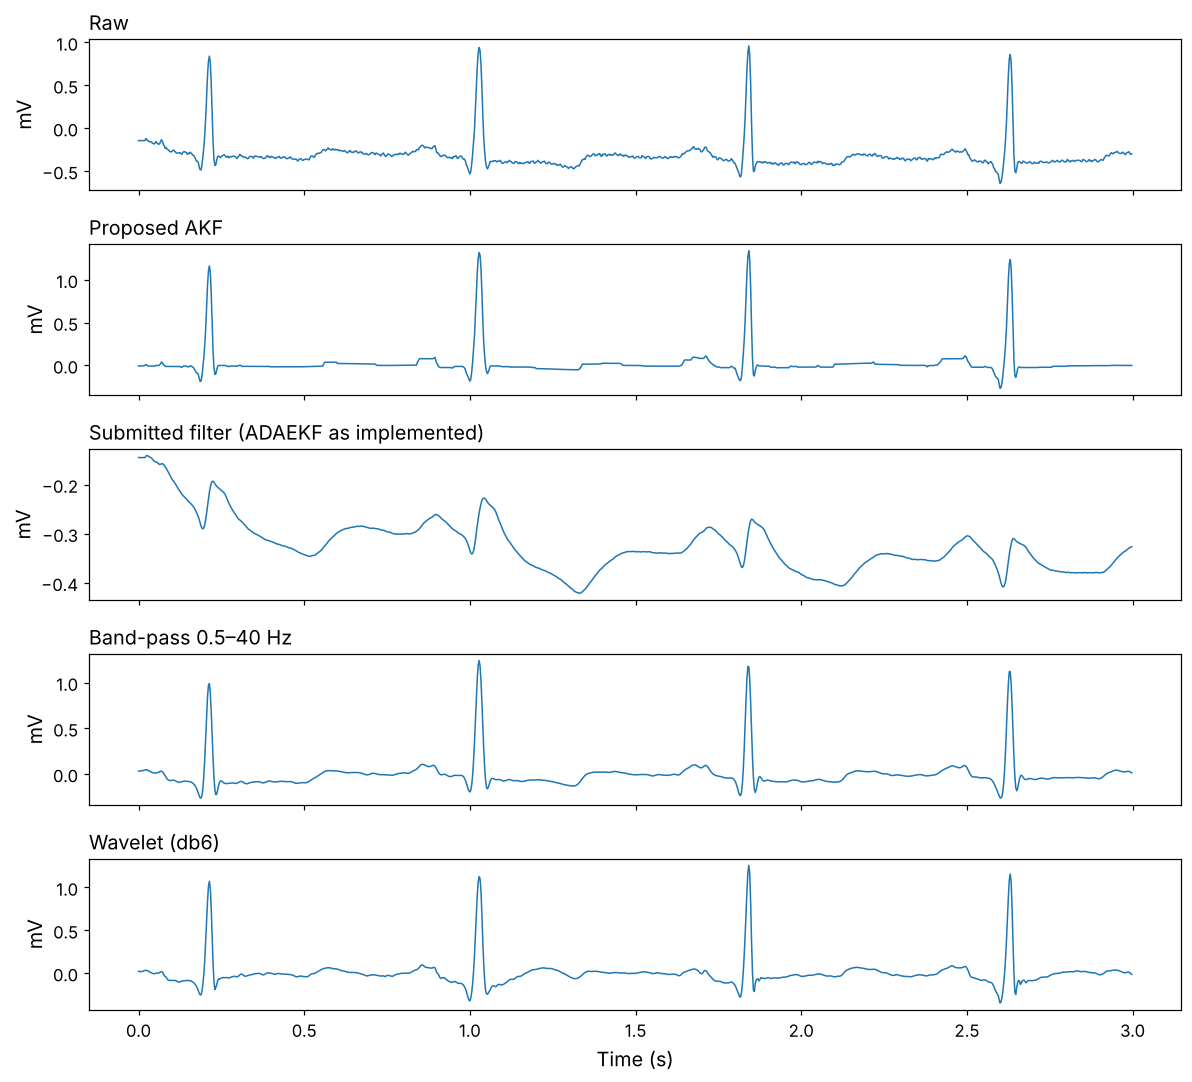

In [15]:
def make_noise(kind, n, fs, rng):
    t = np.arange(n) / fs
    if kind == "white":
        return rng.normal(size=n)
    if kind == "baseline_wander":
        return np.sin(2 * np.pi * 0.15 * t + rng.uniform(0, 6)) + 0.5 * np.sin(2 * np.pi * 0.3 * t + rng.uniform(0, 6))
    if kind == "powerline":
        return np.sin(2 * np.pi * 60 * t + rng.uniform(0, 6))
    if kind == "emg":
        b, a = sps.butter(4, [20 / (fs / 2), 150 / (fs / 2)], "band"); return sps.lfilter(b, a, rng.normal(size=n))
    raise ValueError(kind)

def load_nstdb():
    try:
        os.makedirs("nstdb", exist_ok=True)
        if not os.path.exists("nstdb/bw.hea"):
            wfdb.dl_database("nstdb", "nstdb", records=["bw", "em", "ma"])
        return {k: wfdb.rdrecord(f"nstdb/{k}").p_signal[:, 0] for k in ["bw", "em", "ma"]}
    except Exception as e:
        print("NSTDB not available:", e); return {}

def denoise_benchmark():
    rng = np.random.default_rng(0); fs = CFG["fs"]; rows = []
    recs = [r for r in ["100", "103", "113", "117", "122"] if r in RECORDS_AVAILABLE][:5] or RECORDS_AVAILABLE[:3]
    nst = load_nstdb()
    for rid in recs:
        rec = wfdb.rdrecord(os.path.join(DATA_DIR, rid)); ann = wfdb.rdann(os.path.join(DATA_DIR, rid), "atr")
        clean = rec.p_signal[: 60 * fs, 0]; n = len(clean)
        # reference = clean signal with its own baseline removed (200/600 ms median filters, de Chazal et al. 2004)
        base = sps.medfilt(sps.medfilt(clean, 71), 215); ref = clean - base
        rpk = ann.sample[(ann.sample > 20) & (ann.sample < n - 20)]
        noises = {k: make_noise(k, n, fs, rng) for k in ["white", "baseline_wander", "powerline", "emg"]}
        for k, v in nst.items():
            st = rng.integers(0, len(v) - n); noises[f"NSTDB_{k}"] = v[st: st + n] - v[st: st + n].mean()
        for nk, nz in noises.items():
            for snr_in in [0, 5, 10]:
                nz_s = nz * np.sqrt(np.mean(ref ** 2) / (np.mean(nz ** 2) * 10 ** (snr_in / 10)))
                noisy = clean + nz_s
                for meth in ["akf", "adaekf", "bandpass", "wavelet"]:
                    out = DENOISERS[meth](noisy).astype(np.float64)
                    err = out - ref; err = err - np.median(err)
                    snr_out = 10 * np.log10(np.sum(ref ** 2) / np.sum(err ** 2))
                    amp = np.median(np.abs(out[rpk] - np.median(out)) / (np.abs(ref[rpk]) + 1e-9))
                    rows.append(dict(record=rid, noise=nk, snr_in=snr_in, method=meth, snr_out=snr_out,
                                     snr_improvement=snr_out - snr_in, rmse=float(np.sqrt(np.mean(err ** 2))),
                                     prd=float(100 * np.sqrt(np.sum(err ** 2) / np.sum(ref ** 2))), r_amplitude_ratio=float(amp)))
        # distortion of a clean signal (morphology preservation)
        for meth in ["akf", "adaekf", "bandpass", "wavelet"]:
            out = DENOISERS[meth](clean).astype(np.float64); out = out - sps.medfilt(sps.medfilt(out, 71), 215)
            rows.append(dict(record=rid, noise="none(clean)", snr_in=np.inf, method=meth,
                             r_amplitude_ratio=float(np.median(np.abs(out[rpk]) / (np.abs(ref[rpk]) + 1e-9))),
                             qrs_corr=float(np.mean([np.corrcoef(out[s-18:s+18], ref[s-18:s+18])[0, 1] for s in rpk]))))
    df = pd.DataFrame(rows); df.to_csv("results/denoise_benchmark_raw.csv", index=False)
    summ = df[df.noise != "none(clean)"].groupby(["noise", "snr_in", "method"])[["snr_out", "snr_improvement", "rmse", "prd", "r_amplitude_ratio"]].mean().round(3)
    summ.to_csv("results/denoise_benchmark.csv")
    clean_s = df[df.noise == "none(clean)"].groupby("method")[["r_amplitude_ratio", "qrs_corr"]].mean().round(4)
    clean_s.to_csv("results/denoise_morphology_preservation.csv")
    return summ, clean_s

if RUN_DENOISE_BENCH:
    t0 = time.time(); dn_summ, dn_clean = denoise_benchmark()
    print(dn_summ.unstack("method")["snr_improvement"]); print(dn_clean)
    # per-sample cost
    x = wfdb.rdrecord(os.path.join(DATA_DIR, RECORDS_AVAILABLE[0])).p_signal[:, 0]
    cost = {}
    for meth in ["akf", "adaekf", "bandpass", "wavelet"]:
        DENOISERS[meth](x[:5000]); t0 = time.time(); DENOISERS[meth](x); cost[meth] = 1e6 * (time.time() - t0) / len(x)
    save_json(dict(us_per_sample=cost, numba=HAVE_NUMBA), "denoise_cost"); print("µs/sample:", cost)
    # illustrative figure
    rid = RECORDS_AVAILABLE[0]; rec = wfdb.rdrecord(os.path.join(DATA_DIR, rid)); seg = rec.p_signal[: 3 * CFG["fs"], 0]
    fig, ax = plt.subplots(5, 1, figsize=(11, 10), sharex=True); t = np.arange(len(seg)) / CFG["fs"]
    for a, (lbl, s) in zip(ax, [("Raw", seg), ("Proposed AKF", akf_denoise(seg)), ("Submitted filter (ADAEKF as implemented)", adaekf_denoise(seg)), ("Band-pass 0.5–40 Hz", bandpass_denoise(seg)), ("Wavelet (db6)", wavelet_denoise(seg, level=6))]):
        a.plot(t, s, lw=1); a.set_ylabel("mV"); a.set_title(lbl, loc="left")
    ax[-1].set_xlabel("Time (s)"); plt.tight_layout(); savefig("fig_denoising_examples"); plt.show()

## 8. Main result and ablation study — Protocol B (inter-patient, leakage-safe)

In [16]:
ABLATIONS = OrderedDict([
    ("Proposed (AKF + GAN + FCM + RR)",  dict()),
    ("w/o denoising (raw)",                 dict(denoise="none")),
    ("Submitted ADAEKF instead of AKF",     dict(denoise="adaekf")),
    ("Band-pass instead of AKF",            dict(denoise="bandpass")),
    ("Wavelet instead of AKF",              dict(denoise="wavelet")),
    ("w/o balancing (imbalanced)",          dict(balance="none")),
    ("Class weights instead of GAN",        dict(balance="cw")),
    ("Random oversampling instead of GAN",  dict(balance="ros")),
    ("SMOTE instead of GAN",                dict(balance="smote")),
    ("w/o FCM (RR only)",                   dict(aux="rr")),
    ("FCM only (no explicit RR)",           dict(aux="fcm")),
    ("Original FCM on raw 260-D beats",     dict(aux="fcm", fcm="raw")),
    ("w/o FCM and RR (beat only)",          dict(aux="none")),
    ("w/o patient normalisation",           dict(patnorm="none")),
    ("Beat normalisation only",             dict(patnorm="beat")),
    ("RR normalisation only",               dict(patnorm="rr")),
    ("Patient template from first 300 beats", dict(pn_window=300)),
])
BASELINES = OrderedDict([
    ("CNN-LSTM (beat + RR, GAN)",           dict(arch="cnn_lstm", aux="rr")),
    ("ResNet-1D (beat + RR, GAN)",          dict(arch="resnet1d", aux="rr")),
    ("Random Forest (PCA + RR, GAN)",       dict(arch="rf", aux="rr")),
])
ORIGINAL_PIPE = OrderedDict([
    ("Submitted pipeline (GAN×1.0, 250 it, raw-FCM, no RR)", dict(denoise="adaekf", gan_ratio=1.0, gan_iters=250, gan_classes="all", aux="fcm", fcm="raw", patnorm="none")),
])

RUNS_B = OrderedDict()
def run_group(group, protocol="B", seeds=None, store=RUNS_B):
    for name, cfg in group.items():
        store[name] = [run_config(name, cfg, s, protocol=protocol) for s in (seeds or CFG["seeds"])]

if RUN_ABLATION:
    # the proposed model of seed 0 is saved for LIME/TFLite
    run_config("Proposed (AKF + GAN + FCM + RR)", {}, 0, "B", save_model=True)
    run_group(ABLATIONS)
if RUN_BASELINES:
    run_group(BASELINES)
if RUN_ORIGINAL_PIPE:
    run_group(ORIGINAL_PIPE)

CLS_B = CLASSES["B"]
tbl_B = summarize(RUNS_B, CLS_B); tbl_B.to_csv("results/table_protocolB_ablation_baselines.csv", index=False)
show_cols = ["Configuration", "accuracy", "macro_f1", "mcc", "kappa", "roc_auc_macro", "pr_auc_macro",
             "S_Se", "S_PPV", "V_Se", "V_PPV", "F_Se", "F_PPV", "params", "train_time_s"]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(tbl_B[show_cols].to_string(index=False))

                                       Configuration     accuracy     macro_f1             mcc           kappa roc_auc_macro pr_auc_macro          S_Se         S_PPV         V_Se         V_PPV          F_Se         F_PPV  params  train_time_s
                     Proposed (AKF + GAN + FCM + RR) 94.18 ± 0.07 61.13 ± 2.93 0.6932 ± 0.0071 0.6899 ± 0.0086  93.72 ± 0.36 65.13 ± 0.58 19.86 ± 10.18  33.30 ± 4.12 94.65 ± 1.62  88.39 ± 6.28 22.68 ± 11.57  73.54 ± 6.71   57732    781.434081
                                 w/o denoising (raw) 95.32 ± 0.41 70.17 ± 3.72 0.7505 ± 0.0240 0.7451 ± 0.0251  96.92 ± 0.57 73.25 ± 2.70  24.20 ± 8.08  45.74 ± 7.93 95.49 ± 0.23  95.60 ± 0.63 45.96 ± 11.46  75.33 ± 3.28   57732    689.457311
                     Submitted ADAEKF instead of AKF 93.64 ± 0.05 52.87 ± 3.22 0.6483 ± 0.0010 0.6377 ± 0.0043  90.07 ± 0.96 57.15 ± 1.96  11.35 ± 5.07  26.13 ± 4.39 85.71 ± 1.12  88.28 ± 3.20  7.90 ± 10.27 57.10 ± 10.05   57732    976.761976
                            

### 8.1 Statistical validation: bootstrap CIs and McNemar tests

In [17]:
def load_pred(r):
    d = np.load(r["pred_path"], allow_pickle=True); return d["prob"], d["y"], d["rec"]

stat_rows = []
ref = RUNS_B["Proposed (AKF + GAN + FCM + RR)"]
p0, y0, g0 = load_pred(ref[0]); pred0 = p0.argmax(1)
ci = cluster_bootstrap(y0, pred0, g0, len(CLS_B))
save_json({k: v for k, v in ci.items()}, "bootstrap_ci_proposed_protocolB")
print("Proposed, record-level bootstrap 95% CI:", {k: tuple(round(100 * x, 2) for x in v) for k, v in ci.items()})
for name, rs in RUNS_B.items():
    if name == "Proposed (AKF + GAN + FCM + RR)":
        continue
    p1, y1, _ = load_pred(rs[0]); pred1 = p1.argmax(1)
    if not np.array_equal(y0, y1):
        print("skip McNemar (different test beats):", name); continue
    c0, c1 = pred0 == y0, pred1 == y1
    tb = [[np.sum(c0 & c1), np.sum(c0 & ~c1)], [np.sum(~c0 & c1), np.sum(~c0 & ~c1)]]
    mc = mcnemar(tb, exact=False, correction=True)
    seeds_delta = [ref[i]["test"]["macro_f1"] - rs[i]["test"]["macro_f1"] for i in range(min(len(ref), len(rs)))]
    stat_rows.append(dict(comparison=f"Proposed vs {name}", proposed_only_correct=int(tb[0][1]), other_only_correct=int(tb[1][0]),
                          mcnemar_chi2=float(mc.statistic), p_value=float(mc.pvalue),
                          delta_macro_f1_mean=float(np.mean(seeds_delta)), delta_macro_f1_std=float(np.std(seeds_delta))))
stat_df = pd.DataFrame(stat_rows); stat_df.to_csv("results/mcnemar_protocolB.csv", index=False)
print(stat_df.round(4).to_string(index=False))

Proposed, record-level bootstrap 95% CI: {'accuracy': (89.01, 97.87), 'macro_f1': (56.17, 68.6), 'mcc': (51.41, 86.87), 'F1_0': (93.79, 98.95), 'F1_1': (15.96, 46.06), 'F1_2': (83.14, 97.34), 'F1_3': (0.0, 50.0), 'Se_0': (95.55, 99.17), 'Se_1': (24.51, 74.21), 'Se_2': (81.69, 97.5), 'Se_3': (0.0, 38.46)}


                                                      comparison  proposed_only_correct  other_only_correct  mcnemar_chi2  p_value  delta_macro_f1_mean  delta_macro_f1_std
                                 Proposed vs w/o denoising (raw)                    541                 806       51.7416   0.0000              -0.0904              0.0653
                     Proposed vs Submitted ADAEKF instead of AKF                    989                 657       66.5620   0.0000               0.0826              0.0286
                            Proposed vs Band-pass instead of AKF                    575                 718       15.5947   0.0001              -0.0376              0.0208
                              Proposed vs Wavelet instead of AKF                    629                 577        2.1567   0.1419               0.0202              0.0524
                          Proposed vs w/o balancing (imbalanced)                    460                 556        8.8829   0.0029          

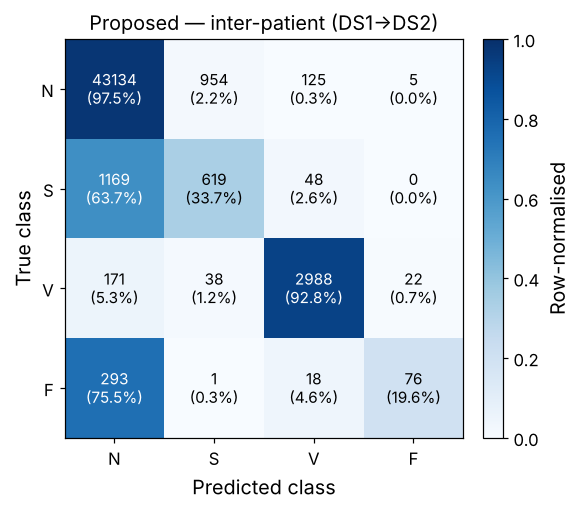

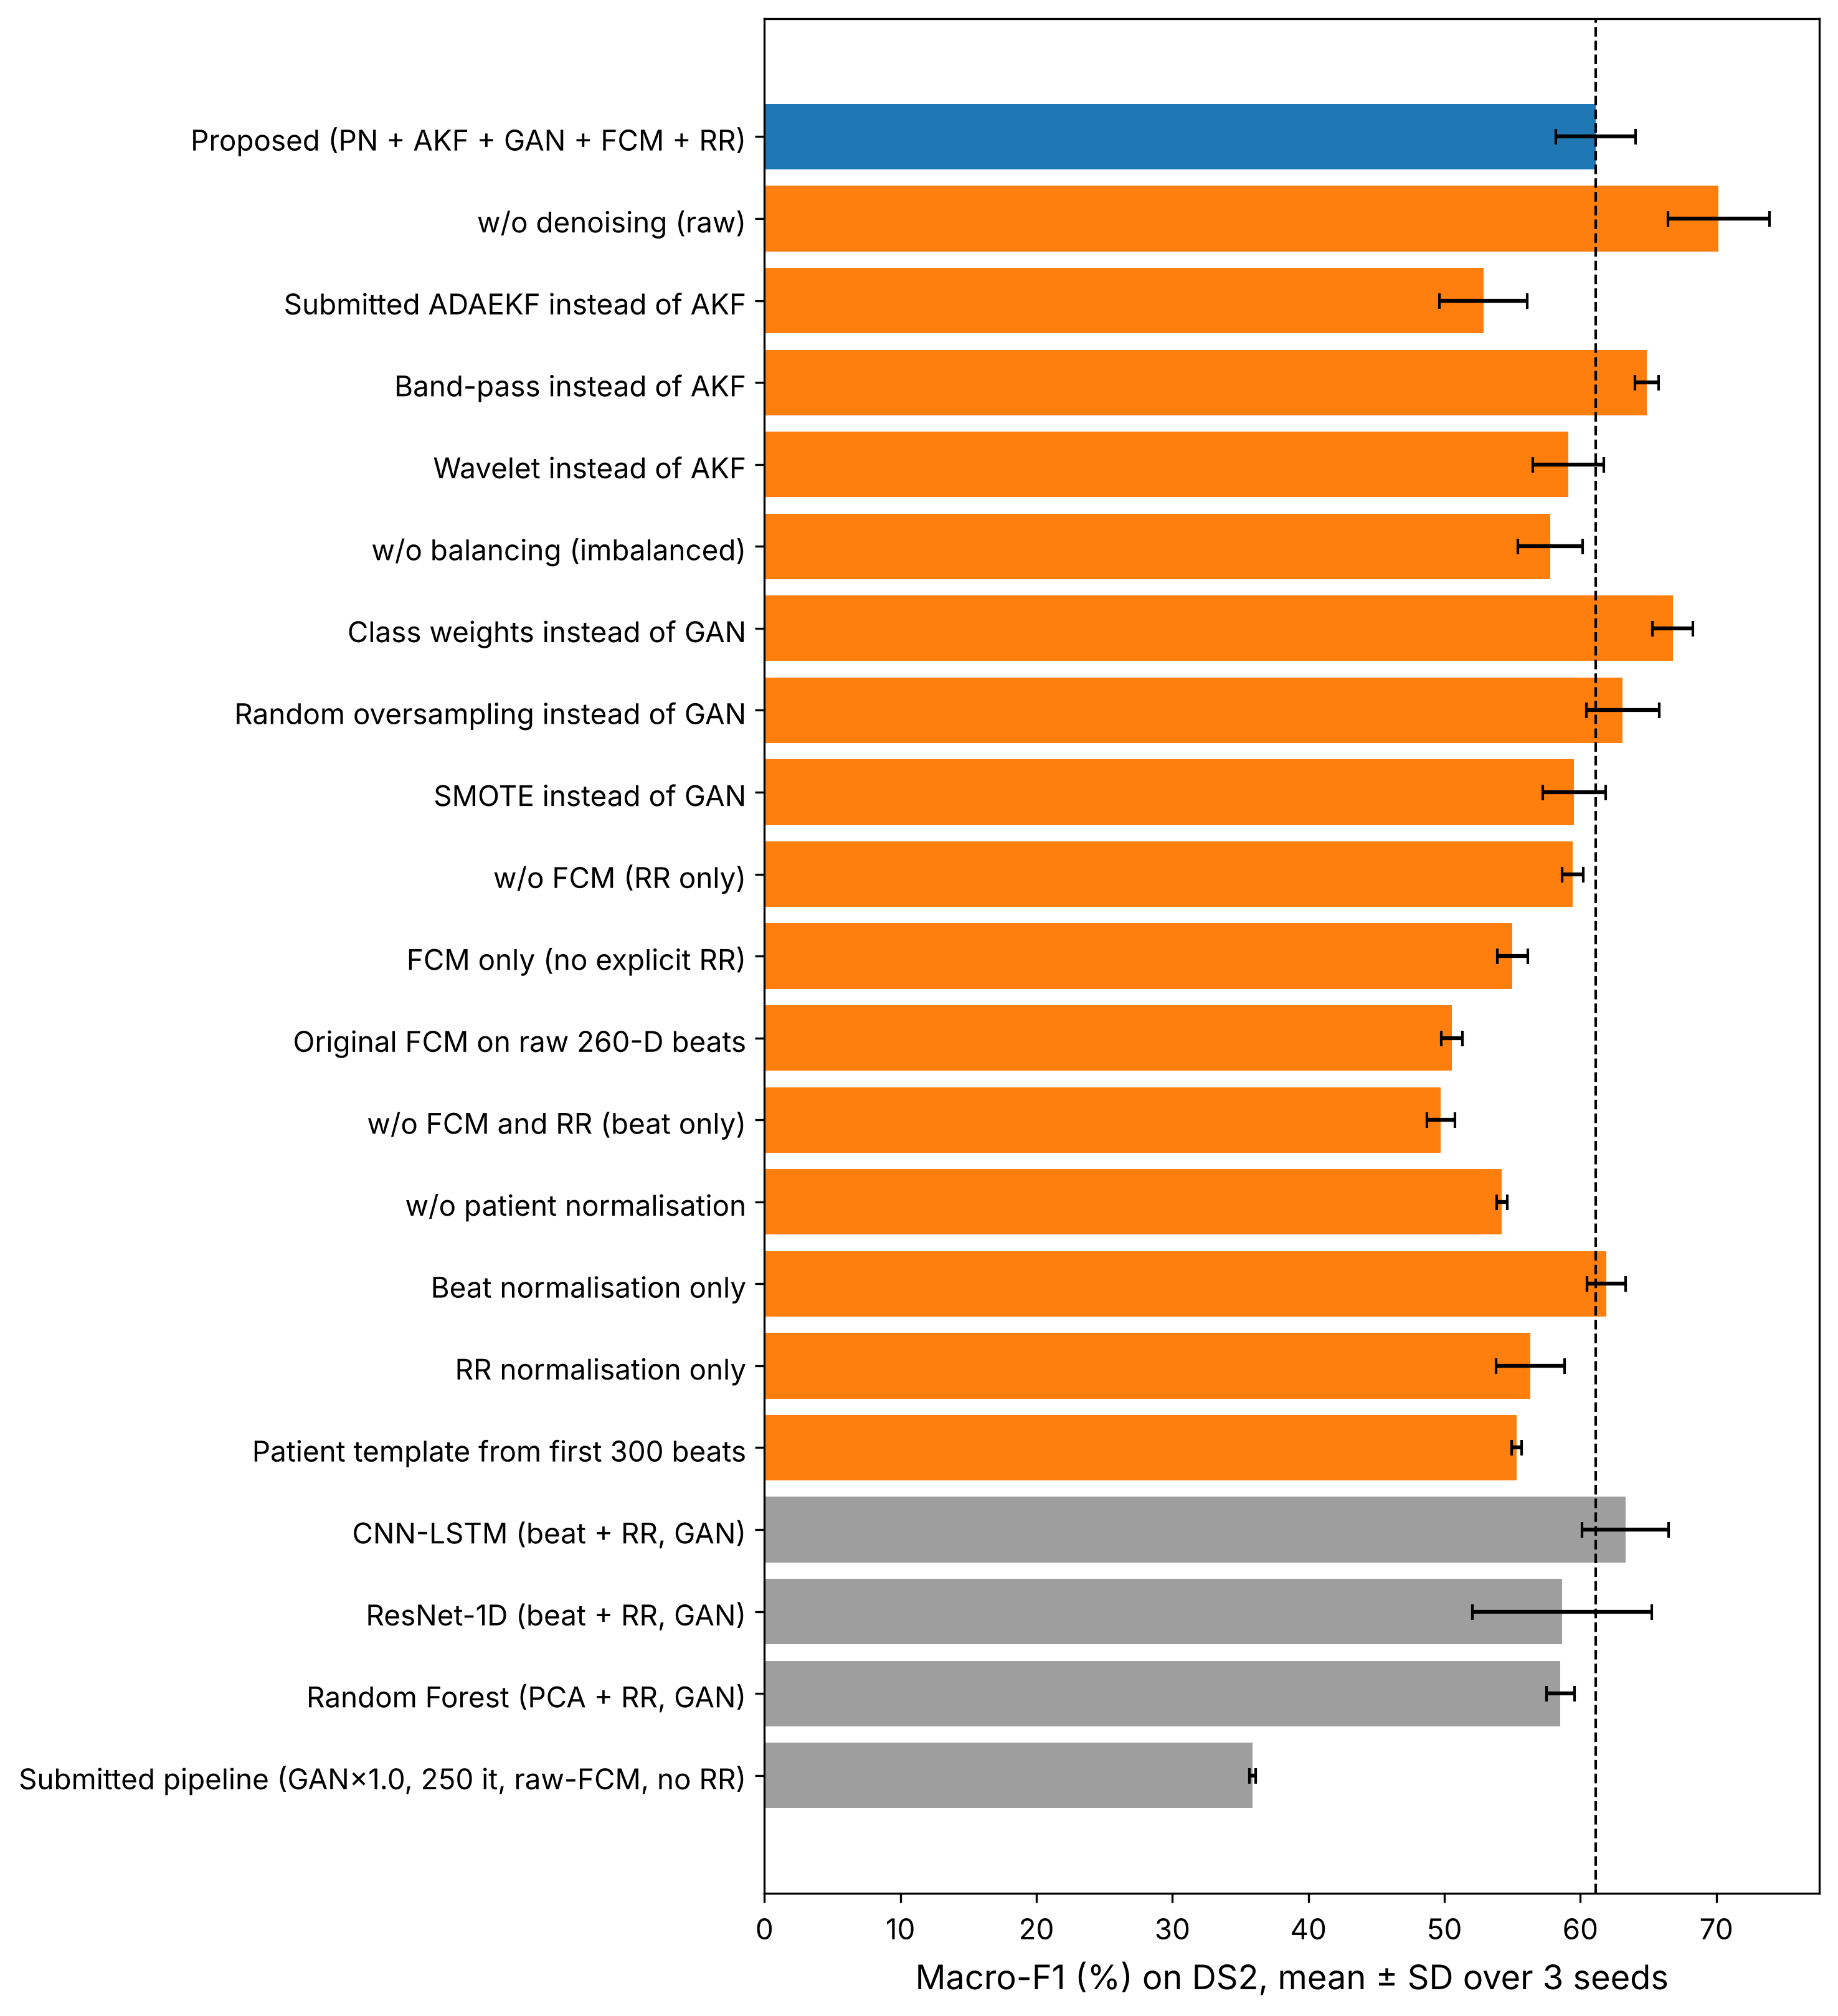

In [18]:
def plot_cm(cm, classes, title, name):
    cm = np.array(cm); cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(5.6, 4.8)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f"{cm[i,j]}\n({100*cmn[i,j]:.1f}%)", ha="center", va="center", fontsize=10,
                    color="white" if cmn[i, j] > 0.6 else "black")
    ax.set_xticks(range(len(classes)), classes); ax.set_yticks(range(len(classes)), classes)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
    plt.colorbar(im, fraction=0.046, pad=0.04, label="Row-normalised"); plt.tight_layout(); savefig(name); plt.show()

plot_cm(ref[0]["test"]["cm"], CLS_B, "Proposed — inter-patient (DS1→DS2)", "fig_cm_proposed_protocolB")

abl = tbl_B.set_index("Configuration")
order = list(ABLATIONS.keys()) + list(BASELINES.keys()) + list(ORIGINAL_PIPE.keys())
order = [o for o in order if o in abl.index]
fig, ax = plt.subplots(figsize=(10, 0.45 * len(order) + 1.5))
vals = [abl.loc[o, "macro_f1_mean"] * 100 for o in order]
errs = [100 * np.std([r["test"]["macro_f1"] for r in RUNS_B[o]]) for o in order]
colors = ["#1f77b4" if o.startswith("Proposed") else "#9e9e9e" if o in BASELINES or o in ORIGINAL_PIPE else "#ff7f0e" for o in order]
ax.barh(range(len(order)), vals, xerr=errs, color=colors, capsize=3); ax.set_yticks(range(len(order)), [o.replace("Proposed (AKF", "Proposed (PN + AKF") for o in order]); ax.invert_yaxis()
ax.set_xlabel("Macro-F1 (%) on DS2, mean ± SD over 3 seeds"); ax.axvline(vals[0], ls="--", c="k", lw=1)
plt.tight_layout(); savefig("fig_ablation_macroF1"); plt.show()

## 9. Reference protocols
### 9.1 Protocol A — intra-patient random beat split (as in the submission; optimistic)
### 9.2 Patient-wise 5-fold cross-validation (all 44 non-paced records, GroupKFold by record)

In [19]:
RUNS_A = OrderedDict()
if RUN_INTRA:
    run_group(OrderedDict([("Proposed (AKF + GAN + FCM + RR)", dict())]), protocol="A", store=RUNS_A)
    run_group(OrderedDict([("w/o FCM (RR only)", dict(aux="rr")),
                           ("Submitted pipeline (GAN×1.0, 250 it, raw-FCM, no RR)", ORIGINAL_PIPE["Submitted pipeline (GAN×1.0, 250 it, raw-FCM, no RR)"])]),
              protocol="A", store=RUNS_A, seeds=CFG["seeds"][:1])
    tbl_A = summarize(RUNS_A, CLASSES["A"]); tbl_A.to_csv("results/table_protocolA_intrapatient.csv", index=False)
    print(tbl_A[["Configuration", "accuracy", "macro_f1", "mcc", "roc_auc_macro", "F_Se", "S_Se"]].to_string(index=False))

CV_RES = []
if RUN_PATIENT_CV:
    recs44 = np.array(DS1 + DS2); gkf = GroupKFold(5)
    for fold, (tri, tei) in enumerate(gkf.split(recs44, groups=recs44)):
        sp = get_split("B", MAIN_DN, seed=0, train_recs=list(recs44[tri]), test_recs=list(recs44[tei])); sp["tag"] = f"cv{fold}"
        r = run_config(f"PatientCV fold{fold}", {}, 0, protocol="B", sp=sp)
        r["test_records"] = list(recs44[tei]); CV_RES.append(r)
    cv_df = pd.DataFrame([{**{k: r["test"][k] for k in ["accuracy", "macro_f1", "mcc", "kappa", "roc_auc_macro", "pr_auc_macro"]},
                           "fold": i, "test_records": " ".join(r["test_records"])} for i, r in enumerate(CV_RES)])
    cv_df.to_csv("results/patient_cv_5fold.csv", index=False)
    print(cv_df.round(4).to_string(index=False)); print("mean ± sd:\n", cv_df.drop(columns=["fold", "test_records"]).agg(["mean", "std"]).round(4))

                                       Configuration     accuracy     macro_f1             mcc roc_auc_macro         F_Se         S_Se
                     Proposed (AKF + GAN + FCM + RR) 99.20 ± 0.07 94.62 ± 0.60 0.9736 ± 0.0024  99.81 ± 0.03 76.88 ± 3.19 89.21 ± 2.29
                                   w/o FCM (RR only) 99.22 ± 0.00 94.84 ± 0.00 0.9744 ± 0.0000  99.80 ± 0.00 78.75 ± 0.00 90.29 ± 0.00
Submitted pipeline (GAN×1.0, 250 it, raw-FCM, no RR) 98.86 ± 0.00 92.95 ± 0.00 0.9621 ± 0.0000  99.43 ± 0.00 71.25 ± 0.00 82.37 ± 0.00


 accuracy  macro_f1    mcc  kappa  roc_auc_macro  pr_auc_macro  fold                        test_records
   0.9549    0.5485 0.6994 0.6795         0.9512        0.5899     0 112 203 105 117 123 210 219 228 234
   0.9679    0.5313 0.7990 0.7926         0.9485        0.6569     1 116 122 209 215 223 103 111 202 233
   0.8761    0.5575 0.5661 0.5516         0.9320        0.6686     2 101 109 115 201 208 121 214 222 232
   0.9510    0.6147 0.7909 0.7874         0.9148        0.5912     3 108 114 119 207 100 200 213 221 231
   0.9872    0.7343 0.8652 0.8633         0.9453        0.7786     4     106 118 124 205 220 230 113 212
mean ± sd:
       accuracy  macro_f1     mcc   kappa  roc_auc_macro  pr_auc_macro
mean    0.9474    0.5973  0.7441  0.7349         0.9384        0.6570
std     0.0423    0.0828  0.1157  0.1217         0.0151        0.0771


## 10. GAN quality assessment (R4.3, R5.4)
For each minority class (Protocol B, seed 0, AKF), synthetic samples are compared with real training beats and with
held-out real validation beats of the same class:
* **Discriminative score** — ROC-AUC of a Random Forest separating real vs synthetic (5-fold CV); 0.5 = indistinguishable.
* **Precision / Recall** (Kynkäänniemi et al., 2019, k=5, PCA-20 space) — fidelity and coverage (mode collapse → low recall).
* **MMD²** (RBF kernel, median heuristic) real-vs-synthetic, compared with real-train-vs-real-validation as reference.
* **Memorisation** — distance from each synthetic sample to its nearest real training sample, relative to the same
  distance for held-out real beats; fraction of synthetic samples closer than the 5th percentile of the real reference.
* **Diversity** — mean pairwise distance synthetic / real.
* **Morphological plausibility** — dominant peak within ±28 ms of the fiducial point, Pearson correlation with the real
  class template, physiological RR range (0.2–2.0 s).

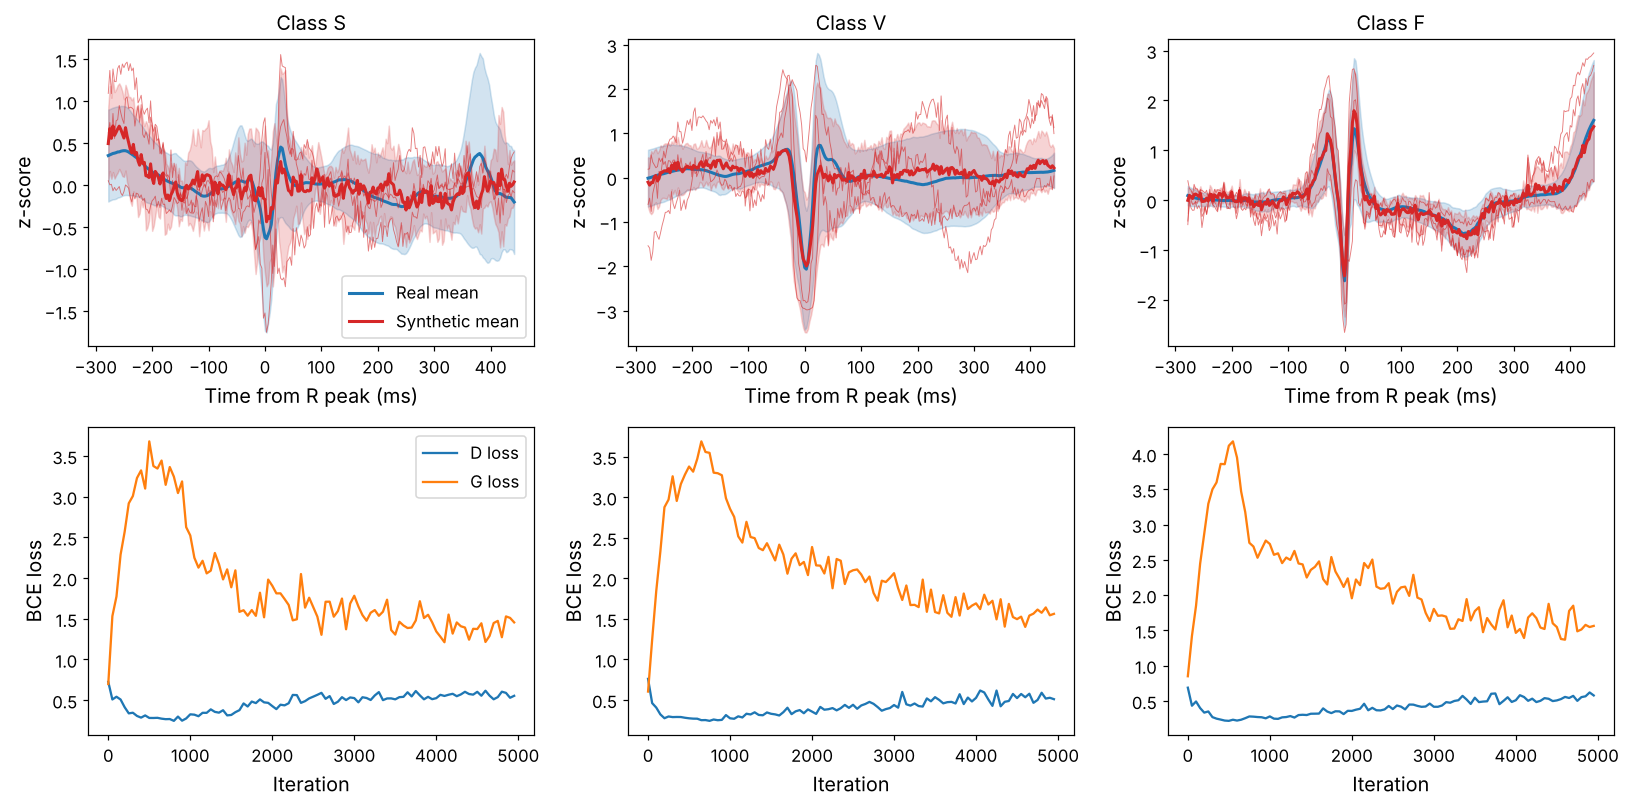

                           0      1      2
cls                        S      V      F
n_real_train             801   3220    352
n_real_val               142    568     62
discriminative_auc       1.0  0.999    1.0
precision              0.635  0.674  0.716
recall                 0.092   0.32  0.335
mmd2_real_vs_syn       0.076  0.044  0.031
mmd2_real_vs_realval   0.006  0.003  0.012
nn_dist_ratio           1.42  4.326  1.396
memorisation_rate        0.0    0.0    0.0
diversity_ratio        0.766  0.963  0.837
template_corr_syn       0.26  0.336   0.78
template_corr_realval    0.3  0.436  0.714
peak_at_fiducial_syn   0.453  0.974  0.611
peak_at_fiducial_real  0.316  0.882  0.639
rr_physiological_syn   0.999  0.974  0.991


In [20]:
def mmd_rbf(A, B, gamma=None):
    Z = np.vstack([A, B]);
    if gamma is None:
        sub = Z[np.random.default_rng(0).choice(len(Z), min(1000, len(Z)), replace=False)]
        d = np.sum((sub[:, None] - sub[None]) ** 2, -1); gamma = 1.0 / np.median(d[d > 0])
    k = lambda X, Y: np.exp(-gamma * np.sum((X[:, None] - Y[None]) ** 2, -1))
    return float(k(A, A).mean() + k(B, B).mean() - 2 * k(A, B).mean())

def prec_recall_knn(real, fake, k=5):
    def radii(X):
        nn = NearestNeighbors(n_neighbors=k + 1).fit(X); return nn.kneighbors(X)[0][:, -1]
    rr_, rf_ = radii(real), radii(fake)
    d_fr = np.sqrt(np.sum((fake[:, None] - real[None]) ** 2, -1))
    precision = float(np.mean(np.any(d_fr <= rr_[None, :], axis=1)))
    recall = float(np.mean(np.any(d_fr.T <= rf_[None, :], axis=1)))
    return precision, recall

def gan_quality(seed=0, n_eval=1000):
    sp = get_split("B", MAIN_DN, seed=seed); sp["protocol"] = "B"
    rr_sc = StandardScaler().fit(sp["tr"]["rr"]); y = sp["tr"]["y"]
    Vtr = to_gan_space(sp["tr"]["X"], rr_sc.transform(sp["tr"]["rr"])); Vva = to_gan_space(sp["va"]["X"], rr_sc.transform(sp["va"]["rr"]))
    pca = PCA(20, random_state=0).fit(Vtr)
    rows, examples = [], {}
    rng = np.random.default_rng(0)
    for k, c in enumerate(CLS_B):
        if c == "N":
            continue
        key = (MAIN_DN, "B", seed, k, CFG["gan_iters"], "", sp["patnorm"])
        if key not in GAN_CACHE:
            GAN_CACHE[key] = train_gan(Vtr[y == k], seed=seed * 100 + k)
        G, hist = GAN_CACHE[key]
        real = Vtr[y == k]; val = Vva[sp["va"]["y"] == k]; n = min(n_eval, len(real))
        real_s = real[rng.choice(len(real), n, replace=False)]; fake = gan_generate(G, n, 123 + k)
        Xr = np.vstack([real_s, fake]); yr = np.r_[np.zeros(n), np.ones(n)]
        disc = float(cross_val_score(RandomForestClassifier(200, n_jobs=-1, random_state=0), Xr, yr, cv=5, scoring="roc_auc").mean())
        Pr, Pf, Pv = pca.transform(real_s), pca.transform(fake), pca.transform(val)
        prec, rec = prec_recall_knn(Pr, Pf)
        nn = NearestNeighbors(n_neighbors=1).fit(pca.transform(real))
        d_fake = nn.kneighbors(Pf)[0][:, 0]; d_val = nn.kneighbors(Pv)[0][:, 0]
        pdist = lambda A: np.mean(np.sqrt(np.sum((A[:300, None] - A[None, :300]) ** 2, -1)))
        Xf_beat, rr_f = from_gan_space(fake); Xr_beat, _ = from_gan_space(real_s)
        rr_f_sec = rr_sc.inverse_transform(rr_f)[:, :2]
        tmpl = Xr_beat.mean(0)
        corr_f = np.mean([np.corrcoef(b, tmpl)[0, 1] for b in Xf_beat]); corr_r = np.mean([np.corrcoef(b, tmpl)[0, 1] for b in from_gan_space(val)[0]])
        peak_ok_f = np.mean(np.abs(np.argmax(np.abs(Xf_beat), 1) - CFG["left"]) <= 10)
        peak_ok_r = np.mean(np.abs(np.argmax(np.abs(Xr_beat), 1) - CFG["left"]) <= 10)
        rows.append(dict(cls=c, n_real_train=int(len(real)), n_real_val=int(len(val)), discriminative_auc=disc,
                         precision=prec, recall=rec, mmd2_real_vs_syn=mmd_rbf(Pr[:500], Pf[:500]),
                         mmd2_real_vs_realval=mmd_rbf(Pr[:500], Pv[:500]),
                         nn_dist_ratio=float(np.median(d_fake) / np.median(d_val)),
                         memorisation_rate=float(np.mean(d_fake < np.percentile(d_val, 5))),
                         diversity_ratio=float(pdist(Pf) / pdist(Pr)), template_corr_syn=float(corr_f), template_corr_realval=float(corr_r),
                         peak_at_fiducial_syn=float(peak_ok_f), peak_at_fiducial_real=float(peak_ok_r),
                         rr_physiological_syn=float(np.mean((rr_f_sec > 0.2) & (rr_f_sec < 2.0)))))
        examples[c] = (Xr_beat[:200], Xf_beat[:200], hist)
    df = pd.DataFrame(rows); df.to_csv("results/gan_quality.csv", index=False)
    # figure: real vs synthetic (mean ± SD band and 5 random examples) + losses
    fig, ax = plt.subplots(2, len(examples), figsize=(5 * len(examples), 7.5))
    t = (np.arange(260) - CFG["left"]) / CFG["fs"] * 1000
    for j, (c, (Rb, Fb, hist)) in enumerate(examples.items()):
        for arr, col, lbl in [(Rb, "C0", "Real"), (Fb, "C3", "Synthetic")]:
            m, s = arr.mean(0), arr.std(0); ax[0, j].plot(t, m, c=col, lw=2, label=f"{lbl} mean"); ax[0, j].fill_between(t, m - s, m + s, color=col, alpha=0.2)
        for i in range(3):
            ax[0, j].plot(t, Fb[i], c="C3", lw=0.6, alpha=0.6)
        ax[0, j].set_title(f"Class {c}"); ax[0, j].set_xlabel("Time from R peak (ms)"); ax[0, j].set_ylabel("z-score")
        h = np.array(hist); ax[1, j].plot(h[:, 0], h[:, 1], label="D loss"); ax[1, j].plot(h[:, 0], h[:, 2], label="G loss")
        ax[1, j].set_xlabel("Iteration"); ax[1, j].set_ylabel("BCE loss")
    ax[0, 0].legend(); ax[1, 0].legend(); plt.tight_layout(); savefig("fig_gan_real_vs_synthetic"); plt.show()
    return df

if RUN_GAN_QUALITY:
    gq = gan_quality(); print(gq.round(3).T)

## 11. FCM analysis (R1, R4.5)
Cluster validity of (a) the submitted FCM (raw 260-D beats) and (b) the corrected feature space, for c = 2…8:
FPC (higher is better; lower bound 1/c), partition entropy PE (lower is better; upper bound ln c), Xie–Beni (lower is better).

                            setting  c      m    FPC  FPC_lower_bound     PE  PE_upper_bound           XB
   Raw 260-D beats, m=2 (submitted)  2 2.0000 0.5657           0.5000 0.6242          0.6931 1.353800e+00
   Raw 260-D beats, m=2 (submitted)  3 2.0000 0.5429           0.3333 0.7640          1.0986 7.446000e-01
   Raw 260-D beats, m=2 (submitted)  4 2.0000 0.4063           0.2500 1.0680          1.3863 1.076500e+00
   Raw 260-D beats, m=2 (submitted)  5 2.0000 0.3291           0.2000 1.2952          1.6094 1.474041e+09
   Raw 260-D beats, m=2 (submitted)  6 2.0000 0.2767           0.1667 1.4840          1.7918 1.052907e+11
   Raw 260-D beats, m=2 (submitted)  7 2.0000 0.2583           0.1429 1.6085          1.9459 7.450171e+05
   Raw 260-D beats, m=2 (submitted)  8 2.0000 0.2379           0.1250 1.7311          2.0794 4.243442e+08
                    PCA-8 + RR, m=2  2 2.0000 0.5000           0.5000 0.6931          0.6931 3.323056e+11
                    PCA-8 + RR, m=2  3 2.0000 

   cluster 1  cluster 2  cluster 3  cluster 4  cluster 5
F      0.583      0.013      0.036      0.328      0.041
N      0.291      0.004      0.332      0.369      0.005
S      0.258      0.072      0.374      0.225      0.071
V      0.065      0.173      0.028      0.046      0.689
raw-beat FCM: membership std across beats = 0.06929939240217209 (≈0 means constant features)


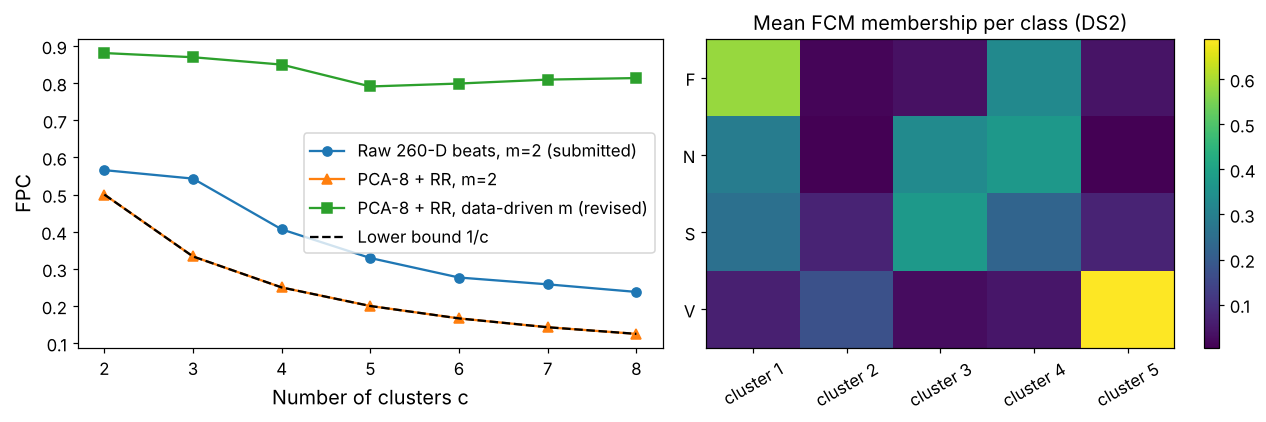

In [21]:
if RUN_FCM_ANALYSIS:
    sp = get_split("B", MAIN_DN, seed=0); rows = []
    for mode, mreq, lbl in [("raw", 2.0, "Raw 260-D beats, m=2 (submitted)"), ("pca_rr", 2.0, "PCA-8 + RR, m=2"), ("pca_rr", "auto", "PCA-8 + RR, data-driven m (revised)")]:
        for c in range(2, 9):
            Xsrc = sp["tr"]["Xraw"] if mode == "raw" else sp["tr"]["X"]   # submitted FCM: un-normalised beats
            fsx = FeatureSpace(mode, c=c, seed=0, m=mreq).fit(Xsrc[:20000], sp["tr"]["rr"][:20000])
            rows.append(dict(setting=lbl, c=c, **fsx.validity))
    fcm_df = pd.DataFrame(rows); fcm_df.to_csv("results/fcm_validity.csv", index=False); print(fcm_df.round(4).to_string(index=False))
    fsx = FeatureSpace("pca_rr", seed=0).fit(sp["tr"]["X"], sp["tr"]["rr"]); fsx_raw = FeatureSpace("raw", seed=0).fit(sp["tr"]["Xraw"][:20000], sp["tr"]["rr"][:20000])
    U = fsx.memberships(sp["te"]["X"], fsx.rr_sc.transform(sp["te"]["rr"])); Uraw = fsx_raw.memberships(sp["te"]["Xraw"][:5000], None)
    mem_tab = pd.DataFrame(U).groupby(np.array(CLS_B)[sp["te"]["y"]]).mean().round(3); mem_tab.columns = [f"cluster {j+1}" for j in range(U.shape[1])]
    mem_tab.to_csv("results/fcm_mean_membership_per_class_test.csv"); print(mem_tab)
    print("raw-beat FCM: membership std across beats =", float(Uraw.std(0).mean()), "(≈0 means constant features)")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for (lbl, s), mk in zip(fcm_df.groupby("setting", sort=False), ["o", "^", "s"]):
        ax[0].plot(s.c, s.FPC, marker=mk, label=lbl)
    ax[0].plot(range(2, 9), [1 / c for c in range(2, 9)], "k--", label="Lower bound 1/c"); ax[0].set_xlabel("Number of clusters c"); ax[0].set_ylabel("FPC"); ax[0].legend()
    im = ax[1].imshow(mem_tab.values, cmap="viridis", aspect="auto"); ax[1].set_yticks(range(len(mem_tab)), mem_tab.index); ax[1].set_xticks(range(mem_tab.shape[1]), mem_tab.columns, rotation=30)
    ax[1].set_title("Mean FCM membership per class (DS2)"); plt.colorbar(im, ax=ax[1]); plt.tight_layout(); savefig("fig_fcm_validity"); plt.show()

## 12. Federated learning (R4.7, R5.5)
* **Clients:** K = 4 hospitals. *Non-IID (patient-wise):* the 22 DS1 patients are randomly assigned to clients
  (5–6 patients each, seed 0), so each client has its own patients and a naturally skewed label distribution (some clients
  have no F beats at all). *IID:* the same training beats are shuffled and split into 4 equal parts.
* **Fully federated preprocessing:** RR/feature scalers (aggregated sums and sums of squares), PCA (aggregated mean and
  scatter matrix) and FCM (server broadcasts centres, clients return $\sum_i u_{ij}^m\mathbf f_i$ and $\sum_i u_{ij}^m$) are
  computed from client sufficient statistics only — mathematically identical to the centralised estimates, no raw data
  leave a client.
* **Local balancing:** each client trains its own class-wise GANs on its local minority beats (only classes with ≥30 local
  beats); synthetic beats never leave the client.
* **Training:** FedAvg (weights ∝ local sample size), 20 communication rounds, all clients participate in every round,
  1 local epoch per round, local Adam (lr 1e-3, re-initialised each round), batch 128. No early stopping (the server holds
  no data); the model after the last round is evaluated on DS2.

                       setting  accuracy  macro_f1    mcc  kappa  roc_auc_macro  pr_auc_macro   S_Se   V_Se   F_Se  comm_MB_total
            Federated (noniid)    0.9449    0.6046 0.7027 0.6965         0.9428        0.6239 0.1683 0.9105 0.2242        36.9485
               Federated (iid)    0.9472    0.6065 0.7186 0.7137         0.9565        0.6693 0.2064 0.9664 0.1495        36.9485
Centralised (proposed, seed 0)    0.9427    0.6430 0.7029 0.7017         0.9325        0.6571 0.3371 0.9282 0.1959            NaN
              N    S     V    F                 patients
Client 1  11917  230  1207  376  122 220 208 112 108 201
Client 2  12040  203   574   21  115 223 109 124 118 101
Client 3  12091   18   761    6      215 203 116 230 114
Client 4   9776  492  1246   11      209 205 119 106 207


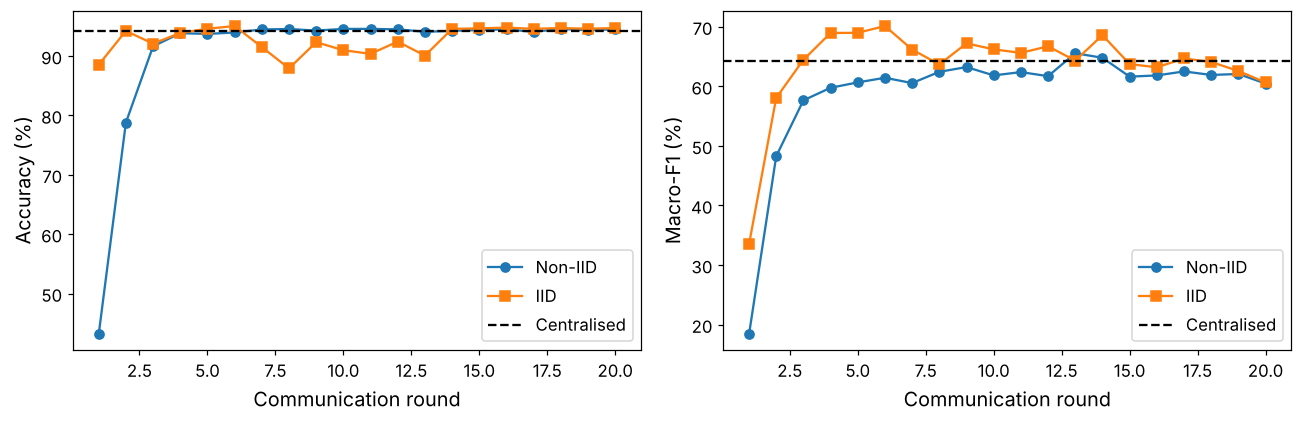

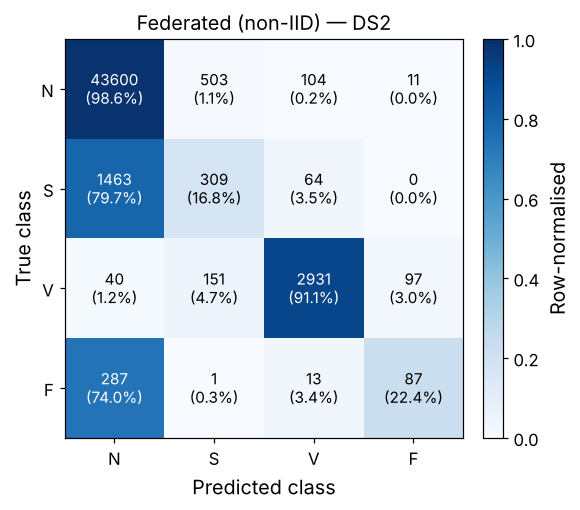

In [22]:
def fed_preprocessing(clients, c, seed, iters=300):
    """Federated RR scaler, PCA and FCM from sufficient statistics."""
    n = sum(len(cl["y"]) for cl in clients)
    rr_mu = sum(cl["rr"].sum(0) for cl in clients) / n
    rr_sd = np.sqrt(sum(((cl["rr"] - rr_mu) ** 2).sum(0) for cl in clients) / n)
    rr_sc = StandardScaler(); rr_sc.mean_, rr_sc.scale_, rr_sc.var_, rr_sc.n_features_in_ = rr_mu, rr_sd, rr_sd ** 2, len(rr_mu)
    mu = sum(cl["X"].astype(np.float64).sum(0) for cl in clients) / n
    S = sum((cl["X"] - mu).T.astype(np.float64) @ (cl["X"] - mu).astype(np.float64) for cl in clients) / n
    w, V = np.linalg.eigh(S); comp = V[:, ::-1][:, :CFG["fcm_pca"]].T
    pca = PCA(CFG["fcm_pca"]); pca.components_, pca.mean_, pca.n_components_ = comp, mu, CFG["fcm_pca"]
    pca.explained_variance_ = w[::-1][:CFG["fcm_pca"]]; pca.whiten = False; pca.n_features_in_ = 260
    raw = lambda cl: np.hstack([pca.transform(cl["X"]), rr_sc.transform(cl["rr"])])
    f_mu = sum(raw(cl).sum(0) for cl in clients) / n
    f_sd = np.sqrt(sum(((raw(cl) - f_mu) ** 2).sum(0) for cl in clients) / n)
    f_sc = StandardScaler(); f_sc.mean_, f_sc.scale_, f_sc.var_, f_sc.n_features_in_ = f_mu, f_sd, f_sd ** 2, len(f_mu)
    F = [f_sc.transform(raw(cl)) for cl in clients]
    m = fuzzifier_sj(min(n, CFG["fcm_fit_max"]), F[0].shape[1]) if CFG["fcm_m"] == "auto" else float(CFG["fcm_m"])
    cntr = np.random.default_rng(seed).normal(size=(c, F[0].shape[1]))
    for it in range(iters):
        num = np.zeros_like(cntr); den = np.zeros(c)
        for Fi in F:                                   # executed locally at each client
            um = fcm_predict(cntr, Fi, m).astype(np.float64) ** m
            num += um.T @ Fi; den += um.sum(0)
        new = num / den[:, None]                       # server aggregation
        if np.max(np.abs(new - cntr)) < CFG["fcm_error"]:
            cntr = new; break
        cntr = new
    fs = FeatureSpace("pca_rr", c=c, seed=seed); fs.rr_sc, fs.pca, fs.f_sc, fs.cntr, fs.m = rr_sc, pca, f_sc, cntr, m
    allF = np.vstack(F)[:20000]; fs.validity = dict(m=m, **fcm_validity(allF, cntr, fcm_predict(cntr, allF, m), m))
    fs.fl_fcm_iterations = it + 1
    return fs

def run_federated(partition="noniid", seed=0, rounds=None, local_epochs=None, balance="local_gan"):
    rounds = rounds or CFG["fl_rounds"]; local_epochs = local_epochs or CFG["fl_local_epochs"]
    tag = f"FL_{partition}_{balance}_s{seed}"
    if os.path.exists(f"cache/{tag}.json"):
        return json.load(open(f"cache/{tag}.json"))
    set_seed(seed); sp = get_split("B", MAIN_DN, seed=seed); K = len(CLS_B)
    tr = {k: np.concatenate([sp["tr"][k], sp["va"][k]]) for k in ["X", "rr", "y", "rec"]}   # no server-side validation in FL
    rng = np.random.default_rng(seed)
    if partition == "noniid":
        recs = np.array(sorted(set(tr["rec"]))); rng.shuffle(recs); groups = np.array_split(recs, CFG["fl_clients"])
        idxs = [np.where(np.isin(tr["rec"], g))[0] for g in groups]
    else:
        perm = rng.permutation(len(tr["y"])); idxs = np.array_split(perm, CFG["fl_clients"]); groups = [None] * CFG["fl_clients"]
    clients = [{k: tr[k][ii] for k in ["X", "rr", "y"]} for ii in idxs]
    dist = pd.DataFrame([np.bincount(cl["y"], minlength=K) for cl in clients], columns=CLS_B, index=[f"Client {i+1}" for i in range(len(clients))])
    dist["patients"] = [" ".join(g) if g is not None else "mixed" for g in groups]
    t0 = time.time(); fs = fed_preprocessing(clients, CFG["fcm_c"], seed); prep_time = time.time() - t0
    # local balancing
    local = []
    for ci, cl in enumerate(clients):
        rrs = fs.rr_sc.transform(cl["rr"]); X, y = cl["X"], cl["y"]; counts = np.bincount(y, minlength=K)
        if balance == "local_gan":
            V = to_gan_space(X, rrs); gv, gy = [], []
            for k in range(K):
                if counts[k] >= 30 and counts[k] < counts.max():
                    need = int(CFG["gan_ratio"] * counts.max()) - counts[k]
                    if need > 0:
                        G, _ = train_gan(V[y == k], seed=seed * 1000 + ci * 10 + k); gv.append(gan_generate(G, need, ci * 10 + k)); gy.append(np.full(need, k))
            if gv:
                Xg, rg = from_gan_space(np.vstack(gv)); X = np.vstack([X, Xg]); rrs = np.vstack([rrs, rg]); y = np.concatenate([y, np.concatenate(gy)])
        local.append(dict(inp=[X[..., None], make_aux(fs, X, rrs, "fcm+rr")], y=np.eye(K)[y], n=len(y)))
    te_inp = [sp["te"]["X"][..., None], make_aux(fs, sp["te"]["X"], fs.rr_sc.transform(sp["te"]["rr"]), "fcm+rr")]
    aux_dim = te_inp[1].shape[1]
    gmodel = build_model("proposed", aux_dim, K); n_params = gmodel.count_params()
    curve = []; t0 = time.time()
    for rnd in range(rounds):
        gw = gmodel.get_weights(); ws, ns = [], []
        for cl in local:
            lm = build_model("proposed", aux_dim, K); lm.set_weights(gw)
            lm.fit(cl["inp"], cl["y"], epochs=local_epochs, batch_size=CFG["fl_batch"], verbose=0, shuffle=True)
            ws.append(lm.get_weights()); ns.append(cl["n"])
        tot = sum(ns); gmodel.set_weights([sum(w[i] * n / tot for w, n in zip(ws, ns)) for i in range(len(gw))])
        prob = gmodel.predict(te_inp, batch_size=2048, verbose=0); mt = compute_metrics(sp["te"]["y"], prob, CLS_B)
        curve.append(dict(round=rnd + 1, accuracy=mt["accuracy"], macro_f1=mt["macro_f1"], mcc=mt["mcc"]))
        print(f"[{partition}] round {rnd+1}/{rounds} acc={mt['accuracy']:.4f} mF1={mt['macro_f1']:.4f}")
    res = dict(partition=partition, balance=balance, seed=seed, rounds=rounds, local_epochs=local_epochs, clients=len(clients),
               client_distribution=dist.to_dict(), curve=curve, test=mt, fl_train_time_s=time.time() - t0, fed_prep_time_s=prep_time,
               fcm_validity=fs.validity, fcm_iterations=fs.fl_fcm_iterations, params=int(n_params),
               comm_MB_per_round=float(2 * len(clients) * n_params * 4 / 1e6), comm_MB_total=float(2 * len(clients) * n_params * 4 * rounds / 1e6))
    if partition == "noniid" and seed == 0:
        gmodel.save("models/FL_noniid_s0.keras")
        import pickle; pickle.dump(dict(fs=fs, classes=CLS_B), open("models/FL_noniid_s0_prep.pkl", "wb"))
    np.savez_compressed(f"cache/pred_{tag}.npz", prob=prob, y=sp["te"]["y"], rec=sp["te"]["rec"])
    json.dump(res, open(f"cache/{tag}.json", "w"), default=lambda o: o.item() if hasattr(o, "item") else str(o))
    return res

if RUN_FL:
    FL = {p: run_federated(p) for p in ["noniid", "iid"]}
    fl_tab = pd.DataFrame([{**{"setting": f"Federated ({p})"}, **{k: v[k] if not isinstance(v.get(k), dict) else None for k in []},
                            **{m: FL[p]["test"][m] for m in ["accuracy", "macro_f1", "mcc", "kappa", "roc_auc_macro", "pr_auc_macro", "S_Se", "V_Se", "F_Se"]},
                            "comm_MB_total": FL[p]["comm_MB_total"]} for p in FL] +
                          [{"setting": "Centralised (proposed, seed 0)", **{m: RUNS_B["Proposed (AKF + GAN + FCM + RR)"][0]["test"][m] for m in ["accuracy", "macro_f1", "mcc", "kappa", "roc_auc_macro", "pr_auc_macro", "S_Se", "V_Se", "F_Se"]}}])
    fl_tab.to_csv("results/federated_vs_centralised.csv", index=False); print(fl_tab.round(4).to_string(index=False))
    print(pd.DataFrame(FL["noniid"]["client_distribution"]))
    pd.DataFrame(FL["noniid"]["client_distribution"]).to_csv("results/fl_client_distribution_noniid.csv")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for p, mk in [("noniid", "o"), ("iid", "s")]:
        cv = pd.DataFrame(FL[p]["curve"]); ax[0].plot(cv["round"], 100 * cv["accuracy"], marker=mk, label=p.upper().replace("NONIID", "Non-IID")); ax[1].plot(cv["round"], 100 * cv["macro_f1"], marker=mk, label=p.upper().replace("NONIID", "Non-IID"))
    c0 = RUNS_B["Proposed (AKF + GAN + FCM + RR)"][0]["test"]
    ax[0].axhline(100 * c0["accuracy"], ls="--", c="k", label="Centralised"); ax[1].axhline(100 * c0["macro_f1"], ls="--", c="k", label="Centralised")
    for a, l in zip(ax, ["Accuracy (%)", "Macro-F1 (%)"]):
        a.set_xlabel("Communication round"); a.set_ylabel(l); a.legend()
    plt.tight_layout(); savefig("fig_federated_rounds"); plt.show()
    plot_cm(FL["noniid"]["test"]["cm"], CLS_B, "Federated (non-IID) — DS2", "fig_cm_federated_noniid")

## 13. Class-wise LIME explanations (R1, R4.10)
For every class, LIME explains correctly classified and misclassified DS2 beats (drawn from as many different patients as
possible). The absolute LIME weights of the 260 time samples are aggregated into ECG regions defined relative to the
R peak (fs = 360 Hz): **P wave** [−250, −120) ms, **PR/Q** [−120, −50) ms, **QRS** [−50, +50) ms, **ST** [+50, +150) ms,
**T wave** [+150, +400) ms, **late** [+400, +444) ms, plus **RR features** and **FCM memberships**.

                    P wave   PR/Q    QRS     ST  T wave   late     RR    FCM  n_beats  n_patients  dominant_consistency most_frequent_dominant
true kind                                                                                                                                     
F    correct         0.017  0.006  0.163  0.010   0.311  0.000  0.460  0.032       10           2                   0.8                     RR
     misclassified   0.254  0.065  0.128  0.086   0.340  0.024  0.096  0.006        5           5                   0.4                 T wave
N    correct         0.304  0.067  0.034  0.080   0.370  0.045  0.062  0.038       10          10                   0.5                 T wave
     misclassified   0.124  0.041  0.038  0.039   0.157  0.032  0.547  0.022        5           5                   0.8                     RR
S    correct         0.242  0.031  0.020  0.018   0.079  0.015  0.542  0.054       10          10                   0.9                     RR

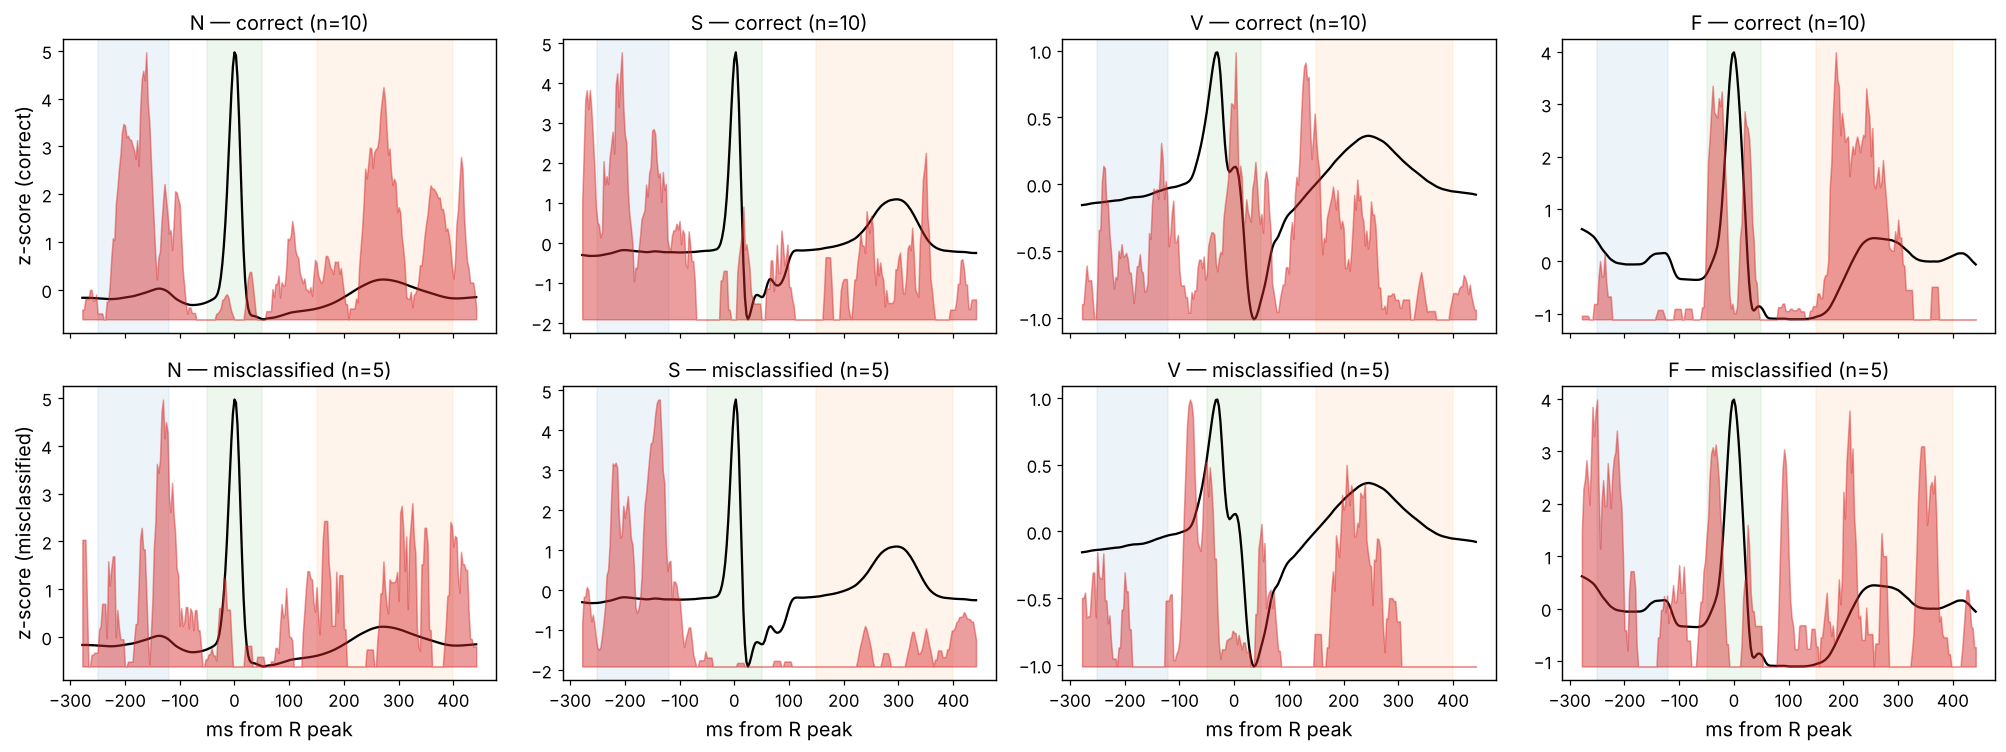

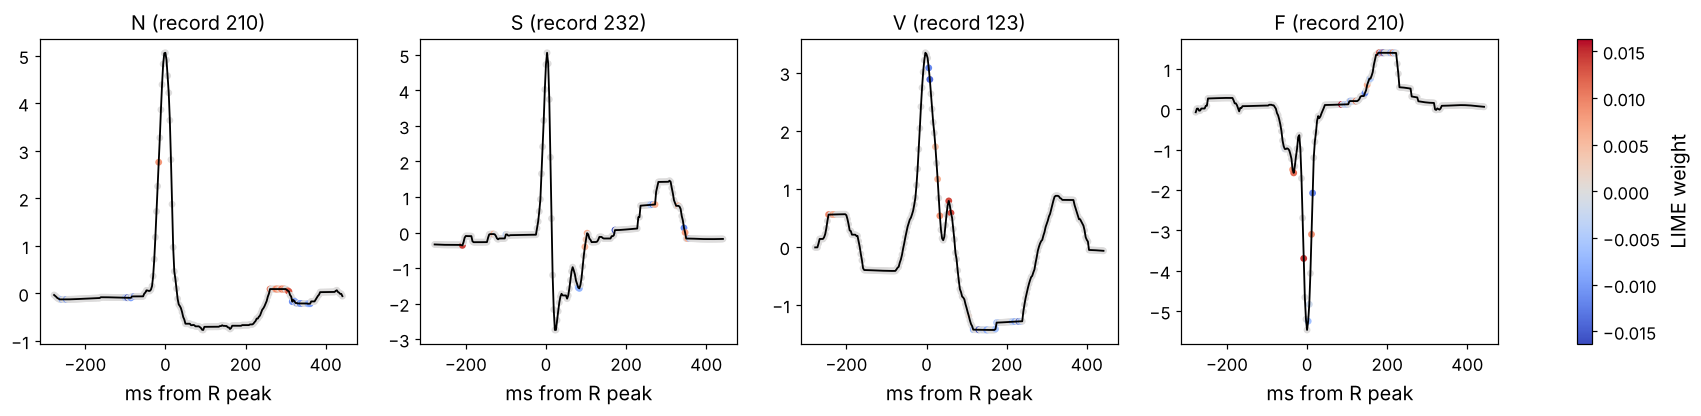

In [23]:
REGIONS = OrderedDict([("P wave", (-250, -120)), ("PR/Q", (-120, -50)), ("QRS", (-50, 50)), ("ST", (50, 150)), ("T wave", (150, 400)), ("late", (400, 445))])
def region_of(i):
    ms = (i - CFG["left"]) / CFG["fs"] * 1000
    for r, (a, b) in REGIONS.items():
        if a <= ms < b:
            return r
    return "P wave" if ms < -250 else "late"

if RUN_LIME:
    import pickle
    model_path = [p for p in glob.glob("models/B__Proposed*s0.keras")][0]
    mdl = keras.models.load_model(model_path); prep = pickle.load(open(model_path.replace(".keras", "_prep.pkl"), "rb"))
    sp = get_split("B", MAIN_DN, seed=0); fsx, rr_sc = prep["fs"], prep["rr_sc"]
    aux_te = make_aux(fsx, sp["te"]["X"], rr_sc.transform(sp["te"]["rr"]), "fcm+rr")
    aux_tr = make_aux(fsx, sp["tr"]["X"][:3000], rr_sc.transform(sp["tr"]["rr"][:3000]), "fcm+rr")
    Xte_l = np.hstack([sp["te"]["X"], aux_te]); Xtr_l = np.hstack([sp["tr"]["X"][:3000], aux_tr])
    rr_names = RR_NAMES + [f"{n}_norm" for n in ("pre_RR", "post_RR", "local_RR")][: sp["te"]["rr"].shape[1] - len(RR_NAMES)]
    fnames = [f"ecg_{i}" for i in range(260)] + [f"fcm_{j}" for j in range(fsx.c)] + rr_names
    groups_f = [region_of(i) for i in range(260)] + ["FCM"] * fsx.c + ["RR"] * len(rr_names)
    assert len(fnames) == Xte_l.shape[1], (len(fnames), Xte_l.shape)
    pred_fn = lambda Z: mdl.predict([Z[:, :260, None].astype(np.float32), Z[:, 260:].astype(np.float32)], batch_size=2048, verbose=0)
    explainer = lime_tabular.LimeTabularExplainer(Xtr_l, feature_names=fnames, class_names=CLS_B, mode="classification",
                                                  discretize_continuous=False, random_state=0)
    prob_te = pred_fn(Xte_l); pred_te = prob_te.argmax(1); yte = sp["te"]["y"]; rec_te = sp["te"]["rec"]
    rng = np.random.default_rng(0); lime_rows = []; W_time = {}
    for k, c in enumerate(CLS_B):
        for kind, mask, nmax in [("correct", (yte == k) & (pred_te == k), CFG["lime_correct"]), ("misclassified", (yte == k) & (pred_te != k), CFG["lime_wrong"])]:
            cand = np.where(mask)[0]
            if len(cand) == 0:
                continue
            # one beat per patient first, then fill
            sel = []
            for r in rng.permutation(np.unique(rec_te[cand])):
                sel.append(rng.choice(cand[rec_te[cand] == r]))
                if len(sel) >= nmax: break
            while len(sel) < min(nmax, len(cand)):
                s = rng.choice(cand); sel.append(s) if s not in sel else None
            for i in sel:
                exp = explainer.explain_instance(Xte_l[i], pred_fn, labels=[int(pred_te[i])], num_features=CFG["lime_features"], num_samples=CFG["lime_samples"])
                w = np.zeros(len(fnames))
                for fi, wt in exp.as_map()[int(pred_te[i])]:
                    w[fi] = wt
                agg = pd.Series(np.abs(w)).groupby(groups_f).sum(); agg = agg / max(agg.sum(), 1e-12)
                lime_rows.append(dict(true=c, pred=CLS_B[pred_te[i]], kind=kind, record=rec_te[i], idx=int(i), **agg.to_dict(), dominant=agg.idxmax()))
                W_time.setdefault((c, kind), []).append(w[:260])
    lime_df = pd.DataFrame(lime_rows).fillna(0); lime_df.to_csv("results/lime_explanations.csv", index=False)
    reg_cols = list(REGIONS.keys()) + ["RR", "FCM"]
    lime_summary = lime_df.groupby(["true", "kind"])[reg_cols].mean().round(3)
    lime_summary["n_beats"] = lime_df.groupby(["true", "kind"]).size(); lime_summary["n_patients"] = lime_df.groupby(["true", "kind"])["record"].nunique()
    lime_summary["dominant_consistency"] = lime_df.groupby(["true", "kind"])["dominant"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).round(3)
    lime_summary["most_frequent_dominant"] = lime_df.groupby(["true", "kind"])["dominant"].agg(lambda s: s.value_counts().index[0])
    lime_summary.to_csv("results/lime_region_summary.csv"); print(lime_summary.to_string())
    # figure: class-wise mean |LIME| over time on the class template
    t = (np.arange(260) - CFG["left"]) / CFG["fs"] * 1000
    fig, axes = plt.subplots(2, len(CLS_B), figsize=(4.6 * len(CLS_B), 7), sharex=True)
    for j, c in enumerate(CLS_B):
        for i_row, kind in enumerate(["correct", "misclassified"]):
            ax = axes[i_row, j]; ax.plot(t, sp["te"]["Xraw"][yte == CLS_B.index(c)].mean(0), c="k", lw=1.5, label=f"Mean {c} beat")
            if (c, kind) in W_time:
                imp = np.abs(np.array(W_time[(c, kind)])).mean(0); imp = sps.convolve(imp, np.ones(5) / 5, mode="same")
                ax2 = ax.twinx(); ax2.fill_between(t, 0, imp, color="C3", alpha=0.45); ax2.set_yticks([])
            for r, (a, b) in REGIONS.items():
                if r in ("P wave", "QRS", "T wave"):
                    ax.axvspan(a, b, color={"P wave": "C0", "QRS": "C2", "T wave": "C1"}[r], alpha=0.08)
            ax.set_title(f"{c} — {kind} (n={len(W_time.get((c, kind), []))})"); ax.set_xlabel("ms from R peak") if i_row else None
    axes[0, 0].set_ylabel("z-score (correct)"); axes[1, 0].set_ylabel("z-score (misclassified)")
    plt.tight_layout(); savefig("fig_lime_classwise"); plt.show()
    # individual example per class
    fig, axes = plt.subplots(1, len(CLS_B), figsize=(4.6 * len(CLS_B), 3.6))
    for j, c in enumerate(CLS_B):
        sub = lime_df[(lime_df.true == c) & (lime_df.kind == "correct")]
        if len(sub) == 0: continue
        i = int(sub.iloc[0]["idx"]); w = np.array(W_time[(c, "correct")][0])
        axes[j].plot(t, sp["te"]["Xraw"][i], c="k", lw=1.2)
        sc = axes[j].scatter(t, sp["te"]["Xraw"][i], c=w, cmap="coolwarm", s=12, vmin=-np.abs(w).max(), vmax=np.abs(w).max())
        axes[j].set_title(f"{c} (record {rec_te[i]})"); axes[j].set_xlabel("ms from R peak")
    plt.colorbar(sc, ax=axes, label="LIME weight", fraction=0.02); savefig("fig_lime_examples"); plt.show()

## 14. TensorFlow Lite offline deployment (R4.11)
FP32, dynamic-range (weights INT8) and full-integer INT8 (representative dataset of 500 training beats) models are
evaluated on the **entire DS2 test set**. Latency: batch size 1, single thread, 2000 invocations after 50 warm-up runs.
Memory: increase of process RSS when the interpreter is created and tensors are allocated. Pre-processing cost per beat
(AKF, RR, FCM memberships) is reported separately.

In [24]:
def tflite_convert(model, mode, rep=None):
    exp_dir = f"models/_export_{mode}"; shutil.rmtree(exp_dir, ignore_errors=True); model.export(exp_dir)
    conv = tf.lite.TFLiteConverter.from_saved_model(exp_dir)
    if mode in ("dynamic", "int8"):
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
    if mode == "int8":
        conv.representative_dataset = rep
    return conv.convert()

def get_interpreter(content, threads=1):
    try:
        from ai_edge_litert.interpreter import Interpreter
    except Exception:
        Interpreter = tf.lite.Interpreter
    return Interpreter(model_content=content, num_threads=threads)

def tflite_eval(content, beats, aux, y, n_lat=2000):
    proc = psutil.Process(); rss0 = proc.memory_info().rss
    it = get_interpreter(content); ins = it.get_input_details(); out = it.get_output_details()[0]
    sig_i = [d for d in ins if len(d["shape"]) == 3][0]["index"]; aux_i = [d for d in ins if len(d["shape"]) == 2][0]["index"]
    B = 256
    it.resize_tensor_input(sig_i, [B, 260, 1]); it.resize_tensor_input(aux_i, [B, aux.shape[1]]); it.allocate_tensors()
    probs = []
    for s in range(0, len(y), B):
        xb, ab = beats[s:s+B], aux[s:s+B]; nb = len(xb)
        if nb < B:
            xb = np.vstack([xb, np.zeros((B - nb, 260), np.float32)]); ab = np.vstack([ab, np.zeros((B - nb, aux.shape[1]), np.float32)])
        it.set_tensor(sig_i, xb[..., None].astype(np.float32)); it.set_tensor(aux_i, ab.astype(np.float32)); it.invoke()
        probs.append(it.get_tensor(out["index"])[:nb].copy())
    prob = np.vstack(probs)
    it1 = get_interpreter(content); it1.allocate_tensors(); rss1 = proc.memory_info().rss
    lat = []
    for i in range(n_lat + 50):
        t0 = time.perf_counter(); it1.set_tensor(sig_i, beats[i % len(beats)][None, :, None].astype(np.float32)); it1.set_tensor(aux_i, aux[i % len(aux)][None].astype(np.float32)); it1.invoke(); _ = it1.get_tensor(out["index"])
        if i >= 50: lat.append((time.perf_counter() - t0) * 1000)
    return prob, dict(latency_ms_mean=float(np.mean(lat)), latency_ms_p95=float(np.percentile(lat, 95)), rss_increase_MB=float((rss1 - rss0) / 1e6))

if RUN_TFLITE:
    import pickle
    tfl_rows = []
    for label, mpath, ppath in [("Centralised", glob.glob("models/B__Proposed*s0.keras")[0], None), ("Federated non-IID", "models/FL_noniid_s0.keras", "models/FL_noniid_s0_prep.pkl")]:
        if not os.path.exists(mpath): continue
        mdl = keras.models.load_model(mpath); prep = pickle.load(open(ppath or mpath.replace(".keras", "_prep.pkl"), "rb"))
        fsx = prep["fs"]; rr_sc = prep.get("rr_sc", fsx.rr_sc)
        sp = get_split("B", MAIN_DN, seed=0); aux_te = make_aux(fsx, sp["te"]["X"], rr_sc.transform(sp["te"]["rr"]), "fcm+rr")
        aux_tr = make_aux(fsx, sp["tr"]["X"][:500], rr_sc.transform(sp["tr"]["rr"][:500]), "fcm+rr")
        keras_prob = mdl.predict([sp["te"]["X"][..., None], aux_te], batch_size=2048, verbose=0)
        km = compute_metrics(sp["te"]["y"], keras_prob, CLS_B)
        tfl_rows.append(dict(model=label, format="Keras FP32 (reference)", size_KB=os.path.getsize(mpath) / 1024, accuracy=km["accuracy"], macro_f1=km["macro_f1"], agreement_with_keras=1.0))
        def rep():
            for i in range(500):
                yield [sp["tr"]["X"][i][None, :, None].astype(np.float32), aux_tr[i][None].astype(np.float32)]
        for mode in ["fp32", "dynamic", "int8"]:
            try:
                content = tflite_convert(mdl, mode, rep); fn = f"models/ecg_{label.split()[0].lower()}_{mode}.tflite"; open(fn, "wb").write(content)
                prob, perf = tflite_eval(content, sp["te"]["X"], aux_te, sp["te"]["y"])
                mt = compute_metrics(sp["te"]["y"], prob, CLS_B)
                tfl_rows.append(dict(model=label, format=f"TFLite {mode}", size_KB=len(content) / 1024, accuracy=mt["accuracy"], macro_f1=mt["macro_f1"],
                                     mcc=mt["mcc"], agreement_with_keras=float(np.mean(prob.argmax(1) == keras_prob.argmax(1))), **perf))
            except Exception as e:
                print(mode, "failed:", e)
    # pre-processing cost per beat
    x = wfdb.rdrecord(os.path.join(DATA_DIR, RECORDS_AVAILABLE[0])).p_signal[:, 0]
    t0 = time.perf_counter(); akf_denoise(x); kf_ms = (time.perf_counter() - t0) * 1000 / (len(x) / (0.8 * CFG["fs"]))
    sp = get_split("B", MAIN_DN, seed=0); rs = rr_sc.transform(sp["te"]["rr"][:1])
    t0 = time.perf_counter()
    for _ in range(1000): fsx.memberships(sp["te"]["X"][:1], rs)
    fcm_ms = (time.perf_counter() - t0)
    tfl_df = pd.DataFrame(tfl_rows); tfl_df.to_csv("results/tflite_deployment.csv", index=False); print(tfl_df.round(4).to_string(index=False))
    save_json(dict(akf_ms_per_beat=kf_ms, fcm_membership_ms_per_beat=fcm_ms, device=ENV["platform"], cpu=ENV["processor"], threads=1), "edge_preprocessing_cost")
    print("AKF ms/beat:", kf_ms, " FCM ms/beat:", fcm_ms)

Saved artifact at 'models/_export_fp32'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 260, 1), dtype=tf.float32, name='beat_input'), TensorSpec(shape=(None, 13), dtype=tf.float32, name='aux_input')]
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  139669919803792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139671078147216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975622096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975620752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975616528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975624400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975619792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975623824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975620944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975621328:

W0000 00:00:1793984695.736708   14708 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793984695.736795   14708 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-11-06 17:04:55.737630: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: models/_export_fp32
2026-11-06 17:04:55.739703: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-11-06 17:04:55.739717: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: models/_export_fp32
I0000 00:00:1793984695.751123   14708 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled
2026-11-06 17:04:55.753650: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-11-06 17:04:55.833211: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: models/_export_fp32
2026-11-06 17:04:55.856493: I tensorflow/cc/saved_model/loader.cc:471] Sa

Saved artifact at 'models/_export_dynamic'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 260, 1), dtype=tf.float32, name='beat_input'), TensorSpec(shape=(None, 13), dtype=tf.float32, name='aux_input')]
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  139669919803792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139671078147216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975622096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975620752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975616528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975624400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975619792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975623824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975620944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1396709756213

W0000 00:00:1793984703.526860   14708 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793984703.526905   14708 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-11-06 17:05:03.527161: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: models/_export_dynamic
2026-11-06 17:05:03.529438: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-11-06 17:05:03.529554: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: models/_export_dynamic
2026-11-06 17:05:03.543882: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-11-06 17:05:03.622546: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: models/_export_dynamic
2026-11-06 17:05:03.644557: I tensorflow/cc/saved_model/loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 117399 microseconds.


Saved artifact at 'models/_export_int8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 260, 1), dtype=tf.float32, name='beat_input'), TensorSpec(shape=(None, 13), dtype=tf.float32, name='aux_input')]
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  139669919803792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139671078147216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975622096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975620752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975616528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975624400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975619792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975623824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975620944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139670975621328:

W0000 00:00:1793984707.327340   14708 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793984707.327389   14708 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-11-06 17:05:07.327611: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: models/_export_int8
2026-11-06 17:05:07.330258: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-11-06 17:05:07.330276: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: models/_export_int8
2026-11-06 17:05:07.345341: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-11-06 17:05:07.442332: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: models/_export_int8
2026-11-06 17:05:07.464327: I tensorflow/cc/saved_model/loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 136719 microseconds.


... (5 outputs left out)

Saved artifact at 'models/_export_int8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 260, 1), dtype=tf.float32, name='beat_input'), TensorSpec(shape=(None, 13), dtype=tf.float32, name='aux_input')]
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  139671921101136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139671921101520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139669919804560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139669919803408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139671921099408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139671921099216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139669919800912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139669919804752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139669919804944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139669919806864:

W0000 00:00:1793984724.665640   14708 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793984724.665684   14708 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-11-06 17:05:24.665981: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: models/_export_int8
2026-11-06 17:05:24.667911: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-11-06 17:05:24.667924: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: models/_export_int8
2026-11-06 17:05:24.680041: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-11-06 17:05:24.751335: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: models/_export_int8
2026-11-06 17:05:24.774599: I tensorflow/cc/saved_model/loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 108622 microseconds.


fully_quantize: 0, inference_type: 6, input_inference_type: FLOAT32, output_inference_type: FLOAT32


            model                 format  size_KB  accuracy  macro_f1  agreement_with_keras    mcc  latency_ms_mean  latency_ms_p95  rss_increase_MB
      Centralised Keras FP32 (reference) 748.6113    0.9427    0.6430                1.0000    NaN              NaN             NaN              NaN
      Centralised            TFLite fp32 233.2422    0.9427    0.6430                1.0000 0.7029           0.1054          0.1375          33.9436
      Centralised         TFLite dynamic  75.1016    0.9427    0.6427                0.9992 0.7030           0.0358          0.0532          23.2694
      Centralised            TFLite int8  77.6719    0.9418    0.5603                0.9793 0.6953           0.0497          0.0657           8.4828
Federated non-IID Keras FP32 (reference) 288.7734    0.9449    0.6046                1.0000    NaN              NaN             NaN              NaN
Federated non-IID            TFLite fp32 233.2539    0.9449    0.6046                1.0000 0.7027        

## 15. Computational complexity summary (R5.11) and export

In [25]:
cx = []
for name, rs in RUNS_B.items():
    if name in ["Proposed (AKF + GAN + FCM + RR)", "w/o FCM and RR (beat only)"] or name in BASELINES or name in ORIGINAL_PIPE:
        r = rs[0]
        cx.append(dict(model=name, params=r.get("params"), flops_per_beat=r.get("flops"), train_samples=r["n_train_after_balancing"],
                       epochs=r.get("epochs"), time_per_epoch_s=r.get("time_per_epoch_s"), train_time_s=r["train_time_s"],
                       gan_time_s=sum((r["balance_info"].get("gan_time_s") or {}).values()) if isinstance(r["balance_info"].get("gan_time_s"), dict) else None,
                       infer_ms_per_beat_batch=r["infer_time_ms_per_beat"], macro_f1=r["test"]["macro_f1"]))
cx_df = pd.DataFrame(cx); cx_df.to_csv("results/complexity.csv", index=False); print(cx_df.round(4).to_string(index=False))

hp = dict(beat_window="100 samples before / 160 after R (722 ms @360 Hz), z-score",
          AKF=dict(baseline="median 200 ms + 600 ms", notch="60 Hz, Q=30", noise_block_s=1.0, q_window=5, q_floor=1e-3, smoother="RTS"),
          submitted_ADAEKF={k: CFG[k] for k in CFG if k.startswith("kf_")},
          GAN=dict(generator="64-128-256-512-265, LeakyReLU(0.2), BN, tanh", discriminator="265-512-256-1, LeakyReLU(0.2), Dropout 0.3, sigmoid",
                   optimizer=f"Adam lr={CFG['gan_lr']}", batch=CFG["gan_batch"], iterations=CFG["gan_iters"], label_smoothing=CFG["gan_label_smooth"],
                   ratio=CFG["gan_ratio"], latent=CFG["gan_latent"]),
          FCM=dict(c=CFG["fcm_c"], m=CFG["fcm_m"], tol=CFG["fcm_error"], maxiter=CFG["fcm_maxiter"], feature_space=f"PCA-{CFG['fcm_pca']} + 5 RR, standardised"),
          classifier=dict(optimizer=f"Adam lr={CFG['lr']}", batch=CFG["batch"], max_epochs=CFG["max_epochs"], early_stopping=f"val_loss, patience {CFG['patience']}",
                          lr_schedule="ReduceLROnPlateau x0.5 patience 2", dropout=0.3, seeds=CFG["seeds"]),
          FL=dict(clients=CFG["fl_clients"], rounds=CFG["fl_rounds"], local_epochs=CFG["fl_local_epochs"], batch=CFG["fl_batch"], aggregation="FedAvg (sample-size weighted)"))
save_json(hp, "hyperparameters")

with zipfile.ZipFile("results_bundle.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob("results/*") + glob.glob("figures/*") + glob.glob("models/*.tflite"):
        z.write(f)
print("results_bundle.zip written")

                                               model  params  flops_per_beat  train_samples  epochs  time_per_epoch_s  train_time_s  gan_time_s  infer_ms_per_beat_batch  macro_f1
                     Proposed (AKF + GAN + FCM + RR)   57732       6066496.0          97375    22.0           50.5020     1111.0449    148.8467                   0.0959    0.6430
                          w/o FCM and RR (beat only)   53188       6057472.0          97375    29.0           49.6565     1440.0391      0.0000                   0.0530    0.5047
                           CNN-LSTM (beat + RR, GAN)   57188       7131392.0          97375    12.0           73.6631      883.9576      0.0000                   0.1912    0.6779
                          ResNet-1D (beat + RR, GAN)  199364      16065024.0          97375    12.0           84.2738     1011.2853      0.0001                   0.2100    0.6794
                       Random Forest (PCA + RR, GAN)  909420             NaN          97375     NaN      

results_bundle.zip written
